### Step 1: Environment Test

In [1]:

# ==========================================
# CELL 1: ENVIRONMENT VERIFICATION
# ==========================================

import sys
import torch
import torchvision
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Python Path:", sys.executable)
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)

print("CUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

    print(
        "GPU Memory:",
        round(
            torch.cuda.get_device_properties(0).total_memory
            / 1024**3, 2
        ),
        "GB"
    )

print("\nENVIRONMENT READY!")


Python Path: <PROJECT_ROOT>\.venv\Scripts\python.exe
PyTorch: 2.14.1+cu130
Torchvision: 0.29.1+cu130
CUDA Available: True
GPU: NVIDIA GeForce RTX 5070 Ti
GPU Memory: 15.89 GB

ENVIRONMENT READY!


### Cell 2: Dataset Configuration

In [2]:

# ==========================================
# CELL 2: DATASET CONFIGURATION
# ==========================================

from pathlib import Path

# Project Directory
PROJECT_DIR = Path.cwd()

# Dataset Directories
DATA_DIR = PROJECT_DIR / "dataset" / "processed"

TRAIN_DIR = DATA_DIR / "train"
VAL_DIR = DATA_DIR / "val"
TEST_DIR = DATA_DIR / "test"

# Model Output Directories
MODEL_DIR = PROJECT_DIR / "models"
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
OUTPUT_DIR = PROJECT_DIR / "outputs"

# Create output directories
MODEL_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Verify Dataset Folders
assert TRAIN_DIR.exists(), f"Training folder not found: {TRAIN_DIR}"
assert VAL_DIR.exists(), f"Validation folder not found: {VAL_DIR}"
assert TEST_DIR.exists(), f"Testing folder not found: {TEST_DIR}"

print("DATASET CONFIGURATION SUCCESSFUL!")

print("\nProject Directory:", PROJECT_DIR)
print("Dataset Directory:", DATA_DIR)

print("\nTraining Directory:", TRAIN_DIR)
print("Validation Directory:", VAL_DIR)
print("Testing Directory:", TEST_DIR)

print("\nModel Directory:", MODEL_DIR)
print("Checkpoint Directory:", CHECKPOINT_DIR)
print("Output Directory:", OUTPUT_DIR)


DATASET CONFIGURATION SUCCESSFUL!

Project Directory: <PROJECT_ROOT>
Dataset Directory: <PROJECT_ROOT>\dataset\processed

Training Directory: <PROJECT_ROOT>\dataset\processed\train
Validation Directory: <PROJECT_ROOT>\dataset\processed\val
Testing Directory: <PROJECT_ROOT>\dataset\processed\test

Model Directory: <PROJECT_ROOT>\models
Checkpoint Directory: <PROJECT_ROOT>\checkpoints
Output Directory: <PROJECT_ROOT>\outputs


PLANTVILLAGE DATASET INFORMATION

Total Classes: 39
Training Images: 43030
Validation Images: 9213
Testing Images: 9243
Total Images: 61486

CLASS DISTRIBUTION TABLE


,Class,Train,Validation,Test,Total
0,Apple___Apple_scab,700,150,150,1000
1,Apple___Black_rot,700,150,150,1000
2,Apple___Cedar_apple_rust,700,150,150,1000
3,Apple___healthy,1151,246,248,1645
4,Background_without_leaves,800,171,172,1143
5,Blueberry___healthy,1051,225,226,1502
6,Cherry___Powdery_mildew,736,157,159,1052
7,Cherry___healthy,700,150,150,1000
8,Corn___Cercospora_leaf_spot Gray_leaf_spot,700,150,150,1000
9,Corn___Common_rust,834,178,180,1192



Largest Training Class:
Orange___Haunglongbing_(Citrus_greening) 3854

Smallest Training Class:
Apple___Apple_scab 700


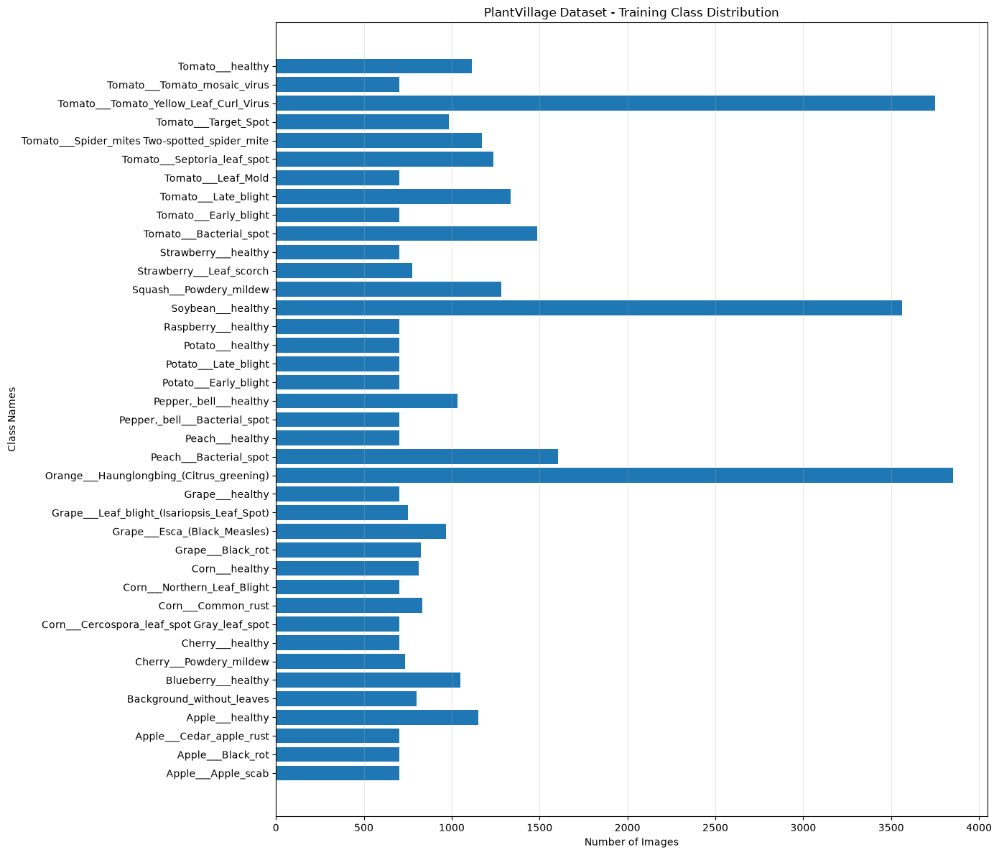


DATASET INFORMATION COMPLETED!


In [4]:

# ==========================================
# CELL 3: DATASET INFORMATION
# ==========================================

from torchvision.datasets import ImageFolder
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Load Dataset Information

train_info = ImageFolder(TRAIN_DIR)
val_info = ImageFolder(VAL_DIR)
test_info = ImageFolder(TEST_DIR)

# Verify Class Consistency

assert train_info.classes == val_info.classes
assert train_info.classes == test_info.classes

class_names = train_info.classes
num_classes = len(class_names)

# Count Images Per Class

train_counts = Counter(train_info.targets)
val_counts = Counter(val_info.targets)
test_counts = Counter(test_info.targets)

# Create DataFrame

data = []

for idx, class_name in enumerate(class_names):

    data.append({
        "Class": class_name,
        "Train": train_counts[idx],
        "Validation": val_counts[idx],
        "Test": test_counts[idx],
        "Total": (
            train_counts[idx]
            + val_counts[idx]
            + test_counts[idx]
        )
    })

df = pd.DataFrame(data)

# ==========================================
# DATASET SUMMARY
# ==========================================

print("=" * 60)
print("PLANTVILLAGE DATASET INFORMATION")
print("=" * 60)

print("\nTotal Classes:", num_classes)

print("Training Images:", len(train_info))
print("Validation Images:", len(val_info))
print("Testing Images:", len(test_info))

print(
    "Total Images:",
    len(train_info) + len(val_info) + len(test_info)
)

print("\nCLASS DISTRIBUTION TABLE")

display(df)

# ==========================================
# LARGEST AND SMALLEST CLASS
# ==========================================

largest_class = df.loc[df["Train"].idxmax()]
smallest_class = df.loc[df["Train"].idxmin()]

print("\nLargest Training Class:")
print(largest_class["Class"], largest_class["Train"])

print("\nSmallest Training Class:")
print(smallest_class["Class"], smallest_class["Train"])

# ==========================================
# CLASS DISTRIBUTION GRAPH
# ==========================================

plt.figure(figsize=(14, 12))

plt.barh(
    df["Class"],
    df["Train"]
)

plt.xlabel("Number of Images")
plt.ylabel("Class Names")

plt.title(
    "PlantVillage Dataset - Training Class Distribution"
)

plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

print("\nDATASET INFORMATION COMPLETED!")


### Image Preprocessing


In [9]:

# ==========================================
# CELL 5: DATASET LOADING & DATALOADER
# EfficientNet-B3
# ==========================================

from torchvision import datasets
from torch.utils.data import DataLoader

# ==========================================
# CONFIGURATION
# ==========================================

BATCH_SIZE = 32
NUM_WORKERS = 0

PIN_MEMORY = torch.cuda.is_available()

# ==========================================
# LOAD TRAINING DATASET
# ==========================================

train_dataset = datasets.ImageFolder(
    root=TRAIN_DIR,
    transform=train_transform
)

# ==========================================
# LOAD VALIDATION DATASET
# ==========================================

val_dataset = datasets.ImageFolder(
    root=VAL_DIR,
    transform=val_transform
)

# ==========================================
# LOAD TEST DATASET
# ==========================================

test_dataset = datasets.ImageFolder(
    root=TEST_DIR,
    transform=test_transform
)

# ==========================================
# CLASS VERIFICATION
# ==========================================

class_names = train_dataset.classes

num_classes = len(class_names)

assert train_dataset.class_to_idx == val_dataset.class_to_idx
assert train_dataset.class_to_idx == test_dataset.class_to_idx

print("Total Classes:", num_classes)

# ==========================================
# CREATE TRAINING DATALOADER
# ==========================================

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY
)

# ==========================================
# CREATE VALIDATION DATALOADER
# ==========================================

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY
)

# ==========================================
# CREATE TEST DATALOADER
# ==========================================

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY
)

# ==========================================
# DATASET SUMMARY
# ==========================================

print("\nDATASET LOADED SUCCESSFULLY!")

print("Training Images:", len(train_dataset))
print("Validation Images:", len(val_dataset))
print("Testing Images:", len(test_dataset))

print("\nDATALOADER INFORMATION")

print("Training Batches:", len(train_loader))
print("Validation Batches:", len(val_loader))
print("Testing Batches:", len(test_loader))

print("\nBatch Size:", BATCH_SIZE)
print("Image Size:", IMG_SIZE)
print("Workers:", NUM_WORKERS)
print("Pin Memory:", PIN_MEMORY)


Total Classes: 39

DATASET LOADED SUCCESSFULLY!
Training Images: 43030
Validation Images: 9213
Testing Images: 9243

DATALOADER INFORMATION
Training Batches: 1345
Validation Batches: 288
Testing Batches: 289

Batch Size: 32
Image Size: 300
Workers: 0
Pin Memory: True


In [11]:

# ==========================================
# CELL 6: IMAGE BATCH VERIFICATION
# ==========================================

images, labels = next(iter(train_loader))

print("Image Batch Shape:", images.shape)
print("Label Batch Shape:", labels.shape)

print("Image Data Type:", images.dtype)
print("Label Data Type:", labels.dtype)

print("Minimum Pixel Value:", images.min().item())
print("Maximum Pixel Value:", images.max().item())

print("Image Size:", images.shape[-2:])
print("Batch Size:", images.shape[0])

print("\nIMAGE BATCH VERIFICATION SUCCESSFUL!")


Image Batch Shape: torch.Size([32, 3, 300, 300])
Label Batch Shape: torch.Size([32])
Image Data Type: torch.float32
Label Data Type: torch.int64
Minimum Pixel Value: -2.1179039478302
Maximum Pixel Value: 2.430849552154541
Image Size: torch.Size([300, 300])
Batch Size: 32

IMAGE BATCH VERIFICATION SUCCESSFUL!


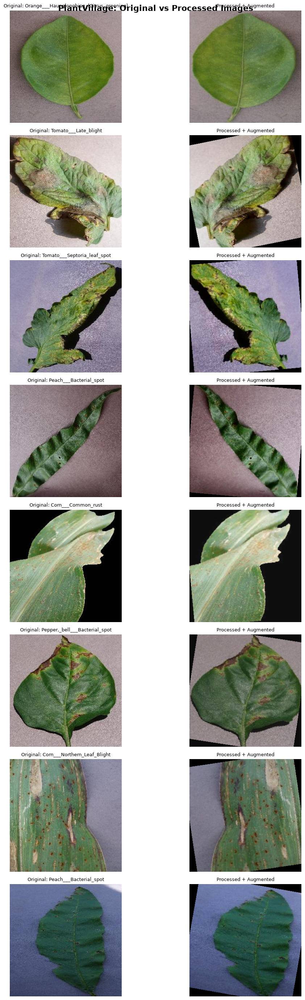

IMAGE PROCESSING VISUALIZATION COMPLETED!
Visualization Saved: <PROJECT_ROOT>\outputs


In [12]:

# ==========================================
# CELL 7: IMAGE PROCESSING VISUALIZATION
# ==========================================

import matplotlib.pyplot as plt
import random
from PIL import Image

# Select 8 Random Images
sample_indices = random.sample(
    range(len(train_dataset.samples)), 8
)

# ImageNet Normalization Parameters
mean = torch.tensor(MEAN).view(3, 1, 1)
std = torch.tensor(STD).view(3, 1, 1)

# Reverse Normalization
def denormalize(image):
    image = image.cpu() * std + mean
    return image.clamp(0, 1)

# Create Visualization
fig, axes = plt.subplots(
    8, 2,
    figsize=(12, 28)
)

for row, idx in enumerate(sample_indices):

    image_path, label = train_dataset.samples[idx]

    # Load Original Image
    original = Image.open(image_path).convert("RGB")

    # Apply Image Processing
    processed = train_transform(original)

    # Reverse Normalization
    processed = denormalize(processed)

    # Original Image
    axes[row, 0].imshow(original)
    axes[row, 0].set_title(
        f"Original: {class_names[label]}",
        fontsize=9
    )
    axes[row, 0].axis("off")

    # Processed Image
    axes[row, 1].imshow(
        processed.permute(1, 2, 0).numpy()
    )
    axes[row, 1].set_title(
        "Processed + Augmented",
        fontsize=9
    )
    axes[row, 1].axis("off")

plt.suptitle(
    "PlantVillage: Original vs Processed Images",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

# Save Visualization
plt.savefig(
    OUTPUT_DIR / "image_processing_visualization.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("IMAGE PROCESSING VISUALIZATION COMPLETED!")
print("Visualization Saved:", OUTPUT_DIR)


### EfficientNet-B3 Model Architecture

In [14]:

# ==========================================
# CELL 8: EFFICIENTNET-B3 MODEL ARCHITECTURE
# ==========================================

import torch
import torch.nn as nn

from torchvision.models import (
    efficientnet_b3,
    EfficientNet_B3_Weights
)

# ==========================================
# MODEL CONFIGURATION
# ==========================================

NUM_CLASSES = 39
MODEL_NAME = "EfficientNet-B3"

# ==========================================
# LOAD PRETRAINED MODEL
# ==========================================

weights = EfficientNet_B3_Weights.DEFAULT

model = efficientnet_b3(weights=weights)

print("Pretrained EfficientNet-B3 Loaded Successfully!")

# ==========================================
# FREEZE BACKBONE
# ==========================================

for param in model.features.parameters():
    param.requires_grad = False

# ==========================================
# REPLACE CLASSIFICATION HEAD
# ==========================================

in_features = model.classifier[1].in_features

model.classifier = nn.Sequential(
    nn.Dropout(p=0.3),
    nn.Linear(in_features, NUM_CLASSES)
)

# ==========================================
# MOVE MODEL TO GPU
# ==========================================
# ==========================================
# GPU DEVICE CONFIGURATION
# ==========================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Selected Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

model = model.to(device)

# ==========================================
# MODEL INFORMATION
# ==========================================

total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

frozen_params = total_params - trainable_params

print("\n" + "=" * 50)
print("EFFICIENTNET-B3 MODEL SUMMARY")
print("=" * 50)

print("Model Name:", MODEL_NAME)
print("Input Size:", IMG_SIZE)
print("Number of Classes:", NUM_CLASSES)
print("Output Features:", in_features)

print("Total Parameters:", f"{total_params:,}")
print("Trainable Parameters:", f"{trainable_params:,}")
print("Frozen Parameters:", f"{frozen_params:,}")

print("Device:", next(model.parameters()).device)

# ==========================================
# MODEL OUTPUT VERIFICATION
# ==========================================

model.eval()

dummy_input = torch.randn(
    2, 3, IMG_SIZE, IMG_SIZE
).to(device)

with torch.no_grad():
    output = model(dummy_input)

print("\nInput Shape:", dummy_input.shape)
print("Output Shape:", output.shape)

assert output.shape == (2, NUM_CLASSES)

model.train()

print("\nEFFICIENTNET-B3 MODEL READY!")


Pretrained EfficientNet-B3 Loaded Successfully!
Selected Device: cuda
GPU: NVIDIA GeForce RTX 5070 Ti

EFFICIENTNET-B3 MODEL SUMMARY
Model Name: EfficientNet-B3
Input Size: 300
Number of Classes: 39
Output Features: 1536
Total Parameters: 10,756,175
Trainable Parameters: 59,943
Frozen Parameters: 10,696,232
Device: cuda:0

Input Shape: torch.Size([2, 3, 300, 300])
Output Shape: torch.Size([2, 39])

EFFICIENTNET-B3 MODEL READY!


### Loss Function & OptimizerLoss Function & Optimizer

In [15]:

# ==========================================
# CELL 9: LOSS FUNCTION & OPTIMIZER
# ==========================================

import torch.nn as nn
import torch.optim as optim

# ==========================================
# LOSS FUNCTION
# ==========================================

criterion = nn.CrossEntropyLoss()

# ==========================================
# OPTIMIZER
# ==========================================

LEARNING_RATE = 0.001
WEIGHT_DECAY = 0.0001

optimizer = optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# ==========================================
# LEARNING RATE SCHEDULER
# ==========================================

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2,
    min_lr=1e-6
)

# ==========================================
# OPTIMIZER INFORMATION
# ==========================================

print("=" * 50)
print("LOSS FUNCTION & OPTIMIZER CONFIGURATION")
print("=" * 50)

print("Loss Function:", criterion)

print("Optimizer:", optimizer.__class__.__name__)

print("Learning Rate:", LEARNING_RATE)

print("Weight Decay:", WEIGHT_DECAY)

print("Scheduler:", scheduler.__class__.__name__)

print(
    "Trainable Parameters:",
    sum(p.numel() for p in model.parameters()
        if p.requires_grad)
)

print("\nOPTIMIZER CONFIGURATION COMPLETED!")


LOSS FUNCTION & OPTIMIZER CONFIGURATION
Loss Function: CrossEntropyLoss()
Optimizer: AdamW
Learning Rate: 0.001
Weight Decay: 0.0001
Scheduler: ReduceLROnPlateau
Trainable Parameters: 59943

OPTIMIZER CONFIGURATION COMPLETED!


### Training Configuration & Mixed Precision (AMP)

In [16]:

# ==========================================
# CELL 10: TRAINING CONFIGURATION
# EfficientNet-B3
# ==========================================

import torch
from pathlib import Path

# ==========================================
# TRAINING PARAMETERS
# ==========================================

EPOCHS = 20

BATCH_SIZE = 32

USE_AMP = (device.type == "cuda")

# ==========================================
# MIXED PRECISION CONFIGURATION
# ==========================================

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=USE_AMP
)

# ==========================================
# CHECKPOINT CONFIGURATION
# ==========================================

BEST_MODEL_PATH = CHECKPOINT_DIR / "best_efficientnet_b3.pth"

LAST_MODEL_PATH = CHECKPOINT_DIR / "last_efficientnet_b3.pth"

# ==========================================
# TRAINING HISTORY
# ==========================================

history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": [],
    "learning_rate": []
}

# ==========================================
# TRAINING STATE
# ==========================================

best_val_acc = 0.0

start_epoch = 0

# ==========================================
# GPU INFORMATION
# ==========================================

if torch.cuda.is_available():

    torch.cuda.empty_cache()

    print("GPU:", torch.cuda.get_device_name(0))

    print(
        "GPU Memory:",
        round(
            torch.cuda.get_device_properties(0).total_memory
            / 1024**3, 2
        ),
        "GB"
    )

# ==========================================
# CONFIGURATION REPORT
# ==========================================

print("\n" + "=" * 50)
print("TRAINING CONFIGURATION")
print("=" * 50)

print("Model: EfficientNet-B3")
print("Epochs:", EPOCHS)
print("Batch Size:", BATCH_SIZE)
print("Image Size:", IMG_SIZE)

print("Mixed Precision:", USE_AMP)
print("Gradient Scaler:", "Enabled" if USE_AMP else "Disabled")

print("Optimizer:", optimizer.__class__.__name__)
print("Loss Function:", criterion.__class__.__name__)

print("Best Model Path:", BEST_MODEL_PATH)
print("Last Model Path:", LAST_MODEL_PATH)

print("\nTRAINING CONFIGURATION READY!")


GPU: NVIDIA GeForce RTX 5070 Ti
GPU Memory: 15.89 GB

TRAINING CONFIGURATION
Model: EfficientNet-B3
Epochs: 20
Batch Size: 32
Image Size: 300
Mixed Precision: True
Gradient Scaler: Enabled
Optimizer: AdamW
Loss Function: CrossEntropyLoss
Best Model Path: <PROJECT_ROOT>\checkpoints\best_efficientnet_b3.pth
Last Model Path: <PROJECT_ROOT>\checkpoints\last_efficientnet_b3.pth

TRAINING CONFIGURATION READY!


### EfficientNet-B3 Training Loop

In [17]:

# ==========================================
# CELL 11: EFFICIENTNET-B3 TRAINING LOOP
# ==========================================

from tqdm.auto import tqdm
import time
import pandas as pd
import torch

# ==========================================
# TRAINING FUNCTION
# ==========================================

def train_one_epoch(model, loader, criterion, optimizer, scaler):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    progress = tqdm(loader, desc="Training", leave=False)

    for images, labels in progress:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=USE_AMP
        ):

            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

        progress.set_postfix(loss=f"{loss.item():.4f}")

    epoch_loss = running_loss / total
    epoch_accuracy = 100.0 * correct / total

    return epoch_loss, epoch_accuracy


# ==========================================
# VALIDATION FUNCTION
# ==========================================

@torch.no_grad()
def validate_one_epoch(model, loader, criterion):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    progress = tqdm(loader, desc="Validation", leave=False)

    for images, labels in progress:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=USE_AMP
        ):

            outputs = model(images)
            loss = criterion(outputs, labels)

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

        progress.set_postfix(loss=f"{loss.item():.4f}")

    epoch_loss = running_loss / total
    epoch_accuracy = 100.0 * correct / total

    return epoch_loss, epoch_accuracy


# ==========================================
# MAIN TRAINING LOOP
# ==========================================

print("=" * 60)
print("EFFICIENTNET-B3 TRAINING STARTED")
print("=" * 60)

print("Device:", device)
print("Epochs:", EPOCHS)

training_start = time.time()

for epoch in range(start_epoch, EPOCHS):

    epoch_start = time.time()

    print("\n" + "=" * 60)
    print(f"EPOCH {epoch + 1}/{EPOCHS}")
    print("=" * 60)

    # Training
    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        scaler
    )

    # Validation
    val_loss, val_acc = validate_one_epoch(
        model,
        val_loader,
        criterion
    )

    # Learning Rate
    current_lr = optimizer.param_groups[0]["lr"]

    # Save History
    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_acc)

    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_acc)

    history["learning_rate"].append(current_lr)

    # Scheduler Update
    scheduler.step(val_acc)

    # Save Last Checkpoint
    checkpoint = {
        "epoch": epoch + 1,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "val_accuracy": val_acc,
        "history": history,
        "class_names": class_names,
        "image_size": IMG_SIZE
    }

    torch.save(checkpoint, LAST_MODEL_PATH)

    # Save Best Model
    if val_acc > best_val_acc:

        best_val_acc = val_acc

        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": model.state_dict(),
                "val_accuracy": val_acc,
                "class_names": class_names,
                "image_size": IMG_SIZE
            },
            BEST_MODEL_PATH
        )

        print("Best Model Saved Successfully!")

    # Epoch Report
    epoch_time = time.time() - epoch_start

    print("\nTRAIN LOSS:", round(train_loss, 4))
    print("TRAIN ACCURACY:", round(train_acc, 2), "%")

    print("VALIDATION LOSS:", round(val_loss, 4))
    print("VALIDATION ACCURACY:", round(val_acc, 2), "%")

    print("BEST VALIDATION ACCURACY:", round(best_val_acc, 2), "%")

    print("LEARNING RATE:", optimizer.param_groups[0]["lr"])

    print("EPOCH TIME:", round(epoch_time / 60, 2), "minutes")

    # Save History CSV
    pd.DataFrame(history).to_csv(
        OUTPUT_DIR / "training_history.csv",
        index=False
    )

# ==========================================
# TRAINING COMPLETED
# ==========================================

total_time = time.time() - training_start

print("\n" + "=" * 60)
print("TRAINING COMPLETED SUCCESSFULLY!")
print("=" * 60)

print("Best Validation Accuracy:", round(best_val_acc, 2), "%")

print("Total Training Time:", round(total_time / 60, 2), "minutes")

print("Best Model:", BEST_MODEL_PATH)
print("Last Model:", LAST_MODEL_PATH)

print("Training History:", OUTPUT_DIR / "training_history.csv")


EFFICIENTNET-B3 TRAINING STARTED
Device: cuda
Epochs: 20

EPOCH 1/20


Training:   0%|          | 0/1345 [00:00<?, ?it/s]

Validation:   0%|          | 0/288 [00:00<?, ?it/s]

Best Model Saved Successfully!

TRAIN LOSS: 0.7568
TRAIN ACCURACY: 84.14 %
VALIDATION LOSS: 0.3303
VALIDATION ACCURACY: 91.84 %
BEST VALIDATION ACCURACY: 91.84 %
LEARNING RATE: 0.001
EPOCH TIME: 5.69 minutes

EPOCH 2/20


Training:   0%|          | 0/1345 [00:00<?, ?it/s]

Validation:   0%|          | 0/288 [00:00<?, ?it/s]

... (51 outputs left out)


TRAIN LOSS: 0.1522
TRAIN ACCURACY: 95.06 %
VALIDATION LOSS: 0.1305
VALIDATION ACCURACY: 95.64 %
BEST VALIDATION ACCURACY: 95.81 %
LEARNING RATE: 0.0005
EPOCH TIME: 5.17 minutes

EPOCH 20/20


Training:   0%|          | 0/1345 [00:00<?, ?it/s]

Validation:   0%|          | 0/288 [00:00<?, ?it/s]


TRAIN LOSS: 0.1532
TRAIN ACCURACY: 94.92 %
VALIDATION LOSS: 0.1258
VALIDATION ACCURACY: 95.81 %
BEST VALIDATION ACCURACY: 95.81 %
LEARNING RATE: 0.00025
EPOCH TIME: 5.02 minutes

TRAINING COMPLETED SUCCESSFULLY!
Best Validation Accuracy: 95.81 %
Total Training Time: 103.74 minutes
Best Model: <PROJECT_ROOT>\checkpoints\best_efficientnet_b3.pth
Last Model: <PROJECT_ROOT>\checkpoints\last_efficientnet_b3.pth
Training History: <PROJECT_ROOT>\outputs\training_history.csv


### Cell 12: Final Model Evaluation


Best Model Loaded Successfully!
Best Epoch: 17
Best Validation Accuracy: 95.81026809942473


Testing:   0%|          | 0/289 [00:00<?, ?it/s]


FINAL TEST RESULTS
Test Images: 9243
Test Loss: 0.1236
Test Accuracy: 95.94 %
Macro Precision: 95.35 %
Macro Recall: 95.37 %
Macro F1-Score: 95.31 %

FINAL TEST EVALUATION COMPLETED!


,precision,recall,f1-score,support
Apple___Apple_scab,0.972028,0.926667,0.948805,150.000000
Apple___Black_rot,0.967532,0.993333,0.980263,150.000000
Apple___Cedar_apple_rust,0.993377,1.000000,0.996678,150.000000
Apple___healthy,0.979839,0.979839,0.979839,248.000000
Background_without_leaves,1.000000,0.994186,0.997085,172.000000
Blueberry___healthy,0.995556,0.991150,0.993348,226.000000
Cherry___Powdery_mildew,1.000000,1.000000,1.000000,159.000000
Cherry___healthy,0.949045,0.993333,0.970684,150.000000
Corn___Cercospora_leaf_spot Gray_leaf_spot,0.886076,0.933333,0.909091,150.000000
Corn___Common_rust,0.994475,1.000000,0.997230,180.000000


Classification Report Saved!


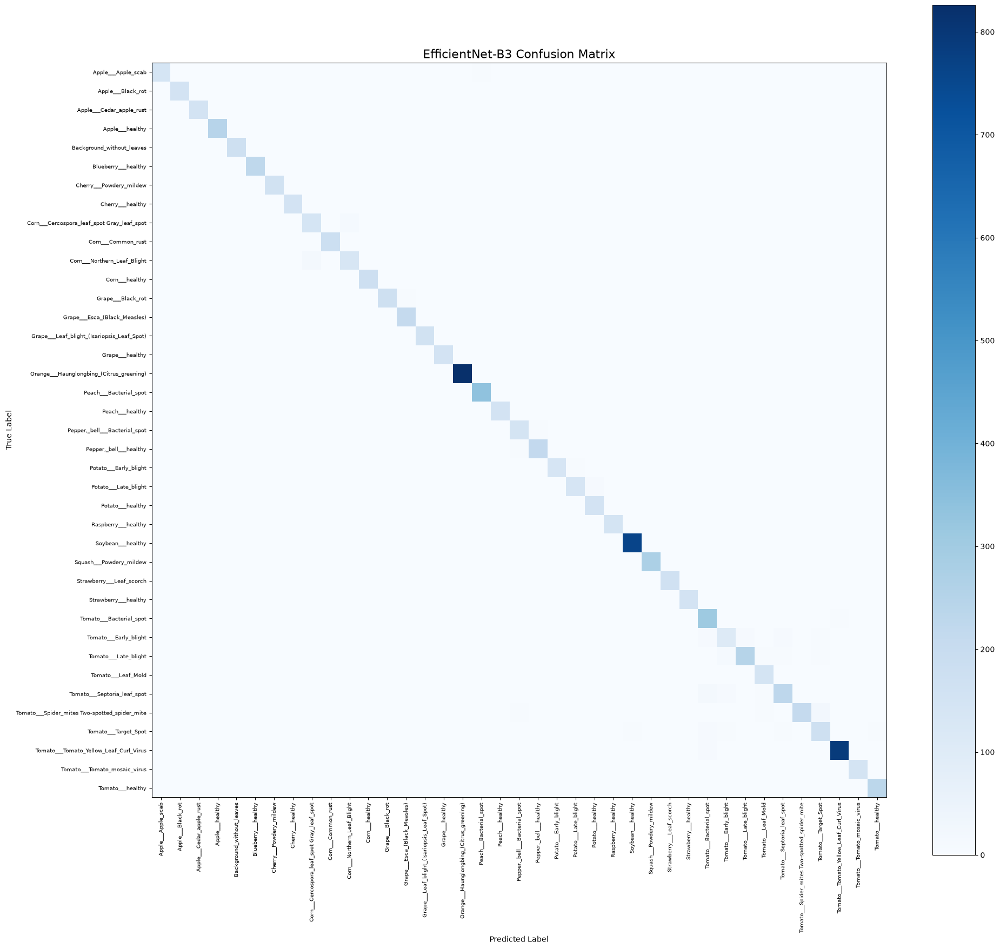

Confusion Matrix Saved!


In [18]:

# ==========================================
# CELL 12: FINAL MODEL EVALUATION
# ==========================================

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tqdm.auto import tqdm
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

# ==========================================
# LOAD BEST MODEL
# ==========================================

checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.to(device)
model.eval()

print("Best Model Loaded Successfully!")
print("Best Epoch:", checkpoint["epoch"])
print("Best Validation Accuracy:", checkpoint["val_accuracy"])

# ==========================================
# TEST EVALUATION
# ==========================================

all_labels = []
all_predictions = []

total_loss = 0.0
total_samples = 0

with torch.inference_mode():

    for images, labels in tqdm(
        test_loader,
        desc="Testing"
    ):

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=USE_AMP
        ):

            outputs = model(images)
            loss = criterion(outputs, labels)

        predictions = outputs.argmax(dim=1)

        total_loss += loss.item() * labels.size(0)
        total_samples += labels.size(0)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())

# ==========================================
# CALCULATE METRICS
# ==========================================

test_loss = total_loss / total_samples

test_accuracy = accuracy_score(
    all_labels,
    all_predictions
) * 100

precision, recall, f1, _ = precision_recall_fscore_support(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

# ==========================================
# FINAL REPORT
# ==========================================

print("\n" + "=" * 55)
print("FINAL TEST RESULTS")
print("=" * 55)

print("Test Images:", total_samples)

print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy, 2), "%")

print("Macro Precision:", round(precision * 100, 2), "%")
print("Macro Recall:", round(recall * 100, 2), "%")
print("Macro F1-Score:", round(f1 * 100, 2), "%")

print("\nFINAL TEST EVALUATION COMPLETED!")

# ==========================================
# CLASSIFICATION REPORT
# ==========================================

report = classification_report(
    all_labels,
    all_predictions,
    target_names=class_names,
    zero_division=0,
    output_dict=True
)

report_df = pd.DataFrame(report).transpose()

display(report_df)

report_df.to_csv(
    OUTPUT_DIR / "classification_report.csv"
)

print("Classification Report Saved!")

# ==========================================
# CONFUSION MATRIX
# ==========================================

cm = confusion_matrix(
    all_labels,
    all_predictions
)

plt.figure(figsize=(20, 18))

plt.imshow(cm, interpolation="nearest", cmap="Blues")

plt.title("EfficientNet-B3 Confusion Matrix", fontsize=16)

plt.colorbar()

ticks = np.arange(len(class_names))

plt.xticks(
    ticks,
    class_names,
    rotation=90,
    fontsize=7
)

plt.yticks(
    ticks,
    class_names,
    fontsize=7
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Confusion Matrix Saved!")


### Training Visualization


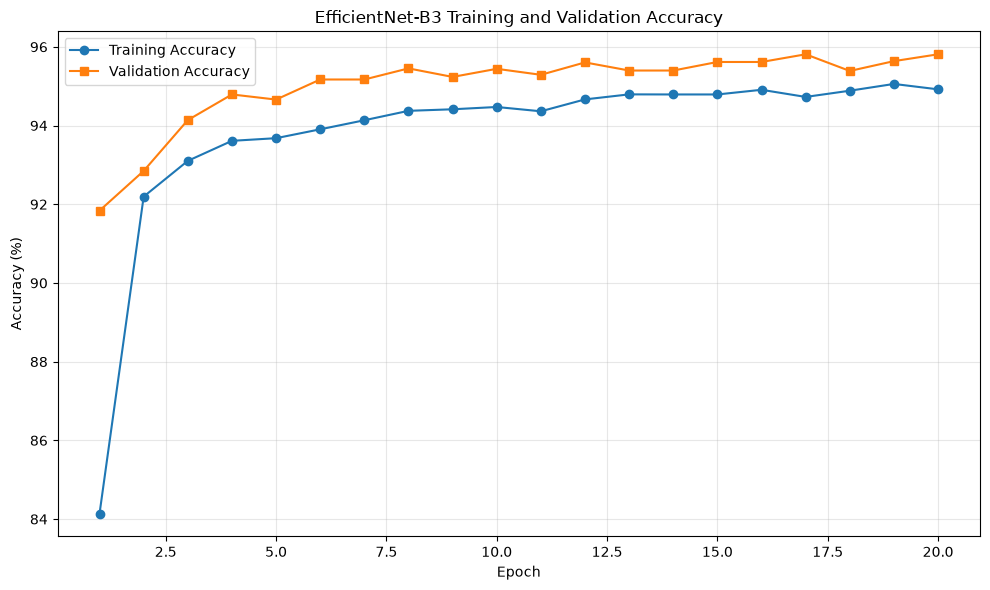

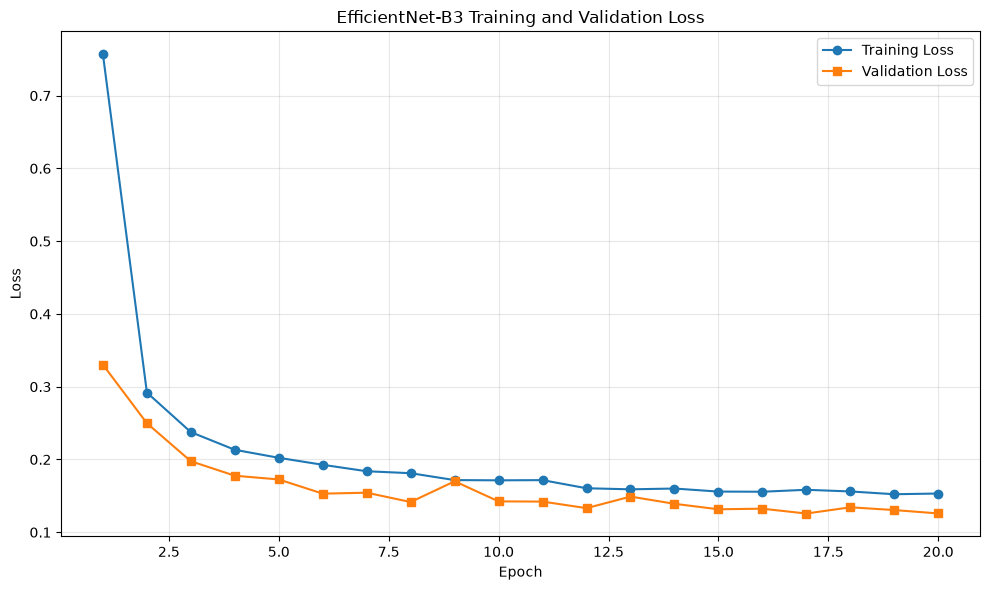

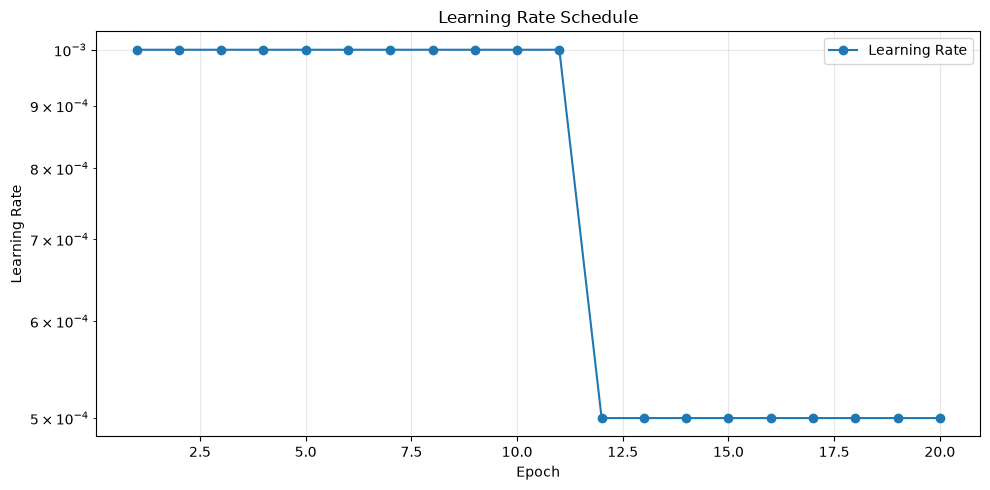

TRAINING VISUALIZATION COMPLETED
Total Epochs: 20
Best Validation Accuracy: 95.81 %
Final Training Accuracy: 94.92 %
Final Validation Accuracy: 95.81 %
Final Test Accuracy: 95.94%

Graphs Saved Successfully!
Output Directory: <PROJECT_ROOT>\outputs


In [19]:

# ==========================================
# CELL 13: TRAINING VISUALIZATION
# ==========================================

import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

# ==========================================
# LOAD TRAINING HISTORY
# ==========================================

history_df = pd.DataFrame(history)

epochs = range(1, len(history_df) + 1)

# ==========================================
# 1. ACCURACY GRAPH
# ==========================================

plt.figure(figsize=(10, 6))

plt.plot(
    epochs,
    history_df["train_accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs,
    history_df["val_accuracy"],
    marker="s",
    label="Validation Accuracy"
)

plt.title("EfficientNet-B3 Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")

plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "accuracy_curve.png",
    dpi=300
)

plt.show()

# ==========================================
# 2. LOSS GRAPH
# ==========================================

plt.figure(figsize=(10, 6))

plt.plot(
    epochs,
    history_df["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs,
    history_df["val_loss"],
    marker="s",
    label="Validation Loss"
)

plt.title("EfficientNet-B3 Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "loss_curve.png",
    dpi=300
)

plt.show()

# ==========================================
# 3. LEARNING RATE GRAPH
# ==========================================

plt.figure(figsize=(10, 5))

plt.plot(
    epochs,
    history_df["learning_rate"],
    marker="o",
    label="Learning Rate"
)

plt.title("Learning Rate Schedule")
plt.xlabel("Epoch")
plt.ylabel("Learning Rate")

plt.yscale("log")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "learning_rate_curve.png",
    dpi=300
)

plt.show()

# ==========================================
# 4. FINAL SUMMARY
# ==========================================

print("=" * 50)
print("TRAINING VISUALIZATION COMPLETED")
print("=" * 50)

print("Total Epochs:", len(history_df))

print("Best Validation Accuracy:",
      round(max(history_df["val_accuracy"]), 2), "%")

print("Final Training Accuracy:",
      round(history_df["train_accuracy"].iloc[-1], 2), "%")

print("Final Validation Accuracy:",
      round(history_df["val_accuracy"].iloc[-1], 2), "%")

print("Final Test Accuracy: 95.94%")

print("\nGraphs Saved Successfully!")

print("Output Directory:", OUTPUT_DIR)


### Confusion Matrix Analysis

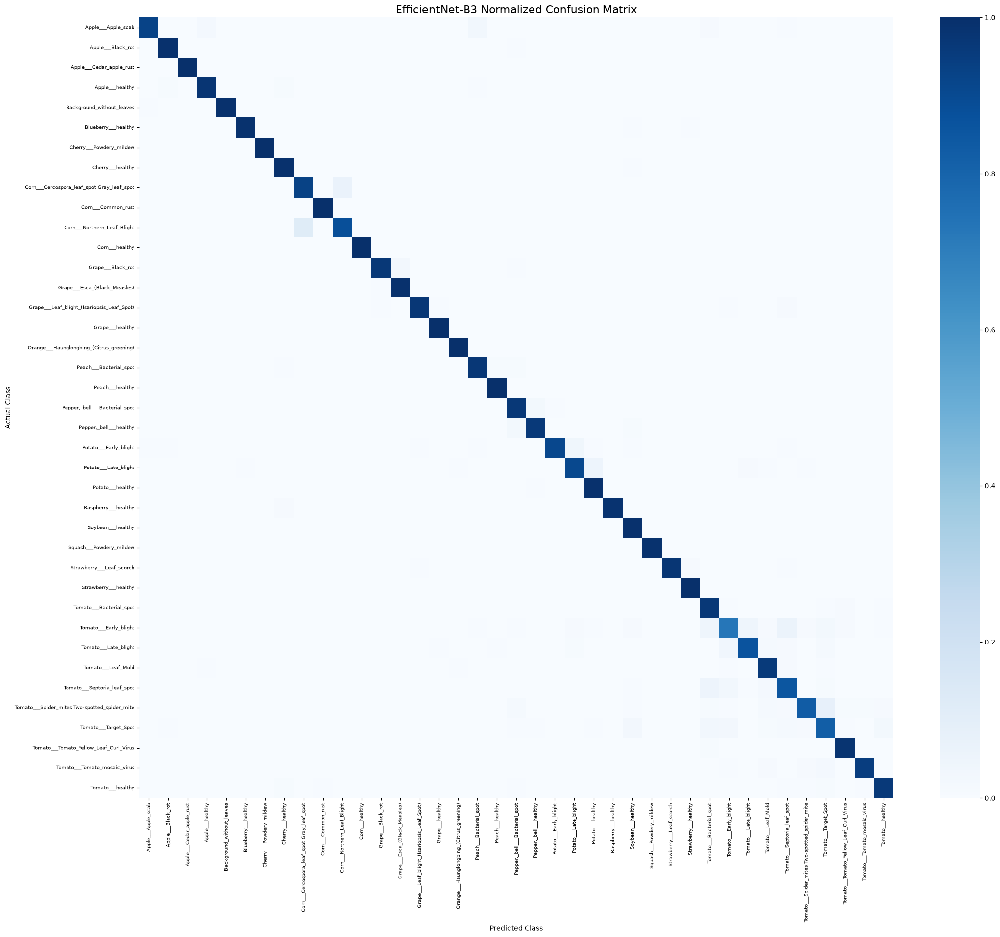


CLASS-WISE ACCURACY


,Class,Correct,Total,Accuracy
2,Apple___Cedar_apple_rust,150,150,100.000000
6,Cherry___Powdery_mildew,159,159,100.000000
28,Strawberry___healthy,150,150,100.000000
15,Grape___healthy,150,150,100.000000
18,Peach___healthy,150,150,100.000000
11,Corn___healthy,175,175,100.000000
9,Corn___Common_rust,180,180,100.000000
16,Orange___Haunglongbing_(Citrus_greening),826,827,99.879081
13,Grape___Esca_(Black_Measles),207,208,99.519231
25,Soybean___healthy,760,764,99.476440


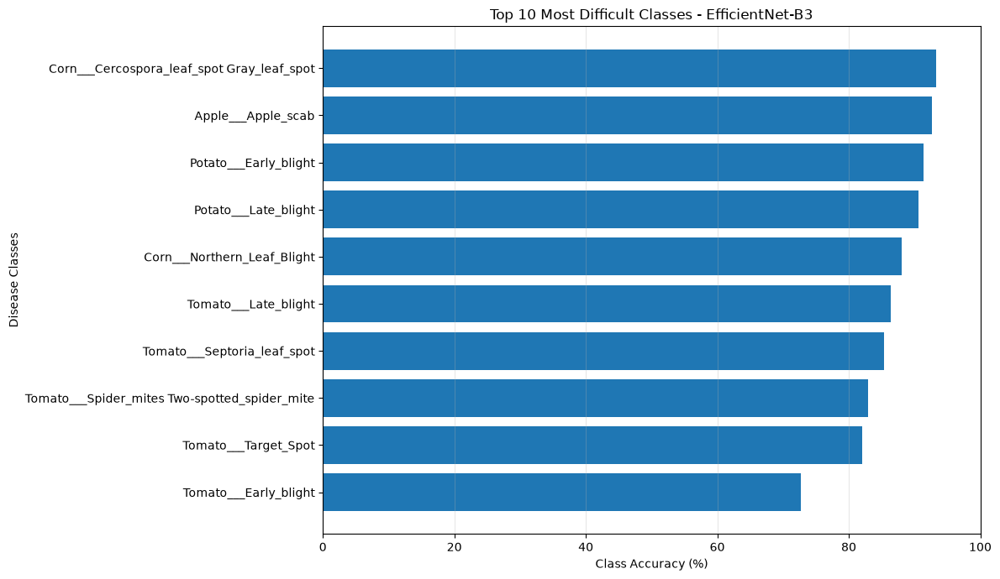


TOP 15 MOST CONFUSED CLASS PAIRS


,Actual Class,Predicted Class,Misclassified Images
108,Tomato___Spider_mites Two-spotted_spider_mite,Tomato___Target_Spot,21
13,Corn___Northern_Leaf_Blight,Corn___Cercospora_leaf_spot Gray_leaf_spot,18
96,Tomato___Septoria_leaf_spot,Tomato___Bacterial_spot,14
83,Tomato___Late_blight,Tomato___Early_blight,11
12,Corn___Cercospora_leaf_spot Gray_leaf_spot,Corn___Northern_Leaf_Blight,10
69,Tomato___Early_blight,Tomato___Septoria_leaf_spot,9
97,Tomato___Septoria_leaf_spot,Tomato___Early_blight,9
41,Potato___Late_blight,Potato___healthy,8
66,Tomato___Early_blight,Tomato___Bacterial_spot,7
67,Tomato___Early_blight,Tomato___Late_blight,7



CONFUSION MATRIX ANALYSIS COMPLETED
Total Classes: 39
Overall Test Accuracy: 95.94 %
Output Directory: <PROJECT_ROOT>\outputs


In [20]:

# ==========================================
# CELL 14: CONFUSION MATRIX ANALYSIS
# ==========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

# ==========================================
# CONFUSION MATRIX
# ==========================================

cm = confusion_matrix(
    all_labels,
    all_predictions
)

# Normalize Confusion Matrix
cm_normalized = cm.astype("float") / np.maximum(
    cm.sum(axis=1, keepdims=True), 1
)

# ==========================================
# 1. NORMALIZED CONFUSION MATRIX
# ==========================================

plt.figure(figsize=(22, 19))

sns.heatmap(
    cm_normalized,
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    vmin=0,
    vmax=1,
    cbar=True
)

plt.title(
    "EfficientNet-B3 Normalized Confusion Matrix",
    fontsize=16
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(rotation=90, fontsize=7)
plt.yticks(rotation=0, fontsize=7)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "normalized_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ==========================================
# 2. CLASS-WISE ACCURACY
# ==========================================

class_correct = np.diag(cm)
class_total = cm.sum(axis=1)

class_accuracy = (
    class_correct / np.maximum(class_total, 1)
) * 100

class_results = pd.DataFrame({
    "Class": class_names,
    "Correct": class_correct,
    "Total": class_total,
    "Accuracy": class_accuracy
})

class_results = class_results.sort_values(
    by="Accuracy",
    ascending=False
)

print("\nCLASS-WISE ACCURACY")
display(class_results)

class_results.to_csv(
    OUTPUT_DIR / "class_wise_accuracy.csv",
    index=False
)

# ==========================================
# 3. TOP 10 MOST MISCLASSIFIED CLASSES
# ==========================================

class_results["Errors"] = (
    class_results["Total"] - class_results["Correct"]
)

worst_classes = class_results.sort_values(
    by="Accuracy",
    ascending=True
).head(10)

plt.figure(figsize=(12, 7))

plt.barh(
    worst_classes["Class"],
    worst_classes["Accuracy"]
)

plt.xlabel("Class Accuracy (%)")
plt.ylabel("Disease Classes")

plt.title(
    "Top 10 Most Difficult Classes - EfficientNet-B3"
)

plt.xlim(0, 100)
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "worst_10_classes.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ==========================================
# 4. MOST CONFUSED CLASS PAIRS
# ==========================================

confused_pairs = []

for i in range(len(class_names)):

    for j in range(len(class_names)):

        if i != j and cm[i, j] > 0:

            confused_pairs.append({
                "Actual Class": class_names[i],
                "Predicted Class": class_names[j],
                "Misclassified Images": cm[i, j]
            })

confused_df = pd.DataFrame(confused_pairs)

confused_df = confused_df.sort_values(
    by="Misclassified Images",
    ascending=False
)

print("\nTOP 15 MOST CONFUSED CLASS PAIRS")

display(confused_df.head(15))

confused_df.to_csv(
    OUTPUT_DIR / "confused_class_pairs.csv",
    index=False
)

# ==========================================
# FINAL REPORT
# ==========================================

print("\n" + "=" * 55)
print("CONFUSION MATRIX ANALYSIS COMPLETED")
print("=" * 55)

print("Total Classes:", len(class_names))

print(
    "Overall Test Accuracy:",
    round(np.trace(cm) / cm.sum() * 100, 2),
    "%"
)

print("Output Directory:", OUTPUT_DIR)


### EfficientNet-B3 Fine-Tuning

In [21]:

# ==========================================
# CELL 15: EFFICIENTNET-B3 FINE-TUNING
# PHASE 2
# ==========================================

import torch
import torch.nn as nn
import torch.optim as optim
import time
import pandas as pd

from tqdm.auto import tqdm

# ==========================================
# 1. LOAD PREVIOUS BEST MODEL
# ==========================================

checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.to(device)

print("Previous Best Model Loaded!")
print("Previous Validation Accuracy:",
      checkpoint["val_accuracy"])

# ==========================================
# 2. FREEZE ALL BACKBONE LAYERS
# ==========================================

for param in model.features.parameters():
    param.requires_grad = False

# ==========================================
# 3. UNFREEZE LAST BACKBONE BLOCKS
# ==========================================

for param in model.features[6:].parameters():
    param.requires_grad = True

# Keep classifier trainable
for param in model.classifier.parameters():
    param.requires_grad = True

# ==========================================
# 4. PARAMETER INFORMATION
# ==========================================

total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("\nFINE-TUNING CONFIGURATION")
print("Total Parameters:", total_params)
print("Trainable Parameters:", trainable_params)
print("Frozen Parameters:", total_params - trainable_params)

# ==========================================
# 5. DIFFERENTIAL LEARNING RATE
# ==========================================

BACKBONE_LR = 0.00001
CLASSIFIER_LR = 0.0001

optimizer_ft = optim.AdamW(
    [
        {
            "params": model.features[6:].parameters(),
            "lr": BACKBONE_LR
        },
        {
            "params": model.classifier.parameters(),
            "lr": CLASSIFIER_LR
        }
    ],
    weight_decay=0.0001
)

scheduler_ft = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_ft,
    mode="max",
    factor=0.5,
    patience=2,
    min_lr=1e-7
)

scaler_ft = torch.amp.GradScaler(
    "cuda",
    enabled=USE_AMP
)

# ==========================================
# 6. FINE-TUNING SETTINGS
# ==========================================

FT_EPOCHS = 10

FT_BEST_PATH = CHECKPOINT_DIR / "best_finetuned_efficientnet_b3.pth"

FT_LAST_PATH = CHECKPOINT_DIR / "last_finetuned_efficientnet_b3.pth"

best_ft_val_acc = -1.0

ft_history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": [],
    "backbone_lr": [],
    "classifier_lr": []
}

# ==========================================
# 7. FINE-TUNING TRAINING FUNCTION
# ==========================================

def train_finetune_epoch():

    model.train()

    # Keep frozen layers and their BatchNorm
    # statistics unchanged
    for layer in model.features[:6]:
        layer.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in tqdm(
        train_loader,
        desc="Fine-tuning Training"
    ):

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer_ft.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=USE_AMP
        ):

            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler_ft.scale(loss).backward()

        scaler_ft.step(optimizer_ft)
        scaler_ft.update()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    return (
        running_loss / total,
        100.0 * correct / total
    )

# ==========================================
# 8. VALIDATION FUNCTION
# ==========================================

@torch.no_grad()
def validate_finetune():

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in tqdm(
        val_loader,
        desc="Fine-tuning Validation"
    ):

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=USE_AMP
        ):

            outputs = model(images)
            loss = criterion(outputs, labels)

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    return (
        running_loss / total,
        100.0 * correct / total
    )

# ==========================================
# 9. MAIN FINE-TUNING LOOP
# ==========================================

print("\n" + "=" * 60)
print("EFFICIENTNET-B3 FINE-TUNING STARTED")
print("=" * 60)

ft_start = time.time()

for epoch in range(FT_EPOCHS):

    epoch_start = time.time()

    print("\n" + "=" * 55)
    print(f"FINE-TUNING EPOCH {epoch + 1}/{FT_EPOCHS}")
    print("=" * 55)

    train_loss, train_acc = train_finetune_epoch()

    val_loss, val_acc = validate_finetune()

    backbone_lr = optimizer_ft.param_groups[0]["lr"]
    classifier_lr = optimizer_ft.param_groups[1]["lr"]

    ft_history["train_loss"].append(train_loss)
    ft_history["train_accuracy"].append(train_acc)

    ft_history["val_loss"].append(val_loss)
    ft_history["val_accuracy"].append(val_acc)

    ft_history["backbone_lr"].append(backbone_lr)
    ft_history["classifier_lr"].append(classifier_lr)

    scheduler_ft.step(val_acc)

    # Save Last Checkpoint
    ft_checkpoint = {
        "epoch": epoch + 1,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer_ft.state_dict(),
        "scaler_state_dict": scaler_ft.state_dict(),
        "val_accuracy": val_acc,
        "class_names": class_names,
        "history": ft_history,
        "image_size": IMG_SIZE
    }

    torch.save(ft_checkpoint, FT_LAST_PATH)

    # Save Best Fine-Tuned Model
    if val_acc > best_ft_val_acc:

        best_ft_val_acc = val_acc

        torch.save(
            ft_checkpoint,
            FT_BEST_PATH
        )

        print("\nBEST FINE-TUNED MODEL SAVED!")

    # Epoch Report
    print("\nTrain Loss:", round(train_loss, 4))
    print("Train Accuracy:", round(train_acc, 2), "%")

    print("Validation Loss:", round(val_loss, 4))
    print("Validation Accuracy:", round(val_acc, 2), "%")

    print("Best Fine-Tuned Accuracy:",
          round(best_ft_val_acc, 2), "%")

    print("Backbone LR:", backbone_lr)
    print("Classifier LR:", classifier_lr)

    print("Epoch Time:",
          round((time.time() - epoch_start) / 60, 2),
          "minutes")

    # Save History
    pd.DataFrame(ft_history).to_csv(
        OUTPUT_DIR / "finetuning_history.csv",
        index=False
    )

# ==========================================
# 10. FINE-TUNING COMPLETED
# ==========================================

ft_total_time = time.time() - ft_start

print("\n" + "=" * 60)
print("FINE-TUNING COMPLETED!")
print("=" * 60)

print("Best Fine-Tuned Validation Accuracy:",
      round(best_ft_val_acc, 2), "%")

print("Fine-Tuning Time:",
      round(ft_total_time / 60, 2), "minutes")

print("Best Model:", FT_BEST_PATH)
print("Last Model:", FT_LAST_PATH)

print("FINE-TUNING HISTORY SAVED!")


Previous Best Model Loaded!
Previous Validation Accuracy: 95.81026809942473

FINE-TUNING CONFIGURATION
Total Parameters: 10756175
Trainable Parameters: 8566021
Frozen Parameters: 2190154

EFFICIENTNET-B3 FINE-TUNING STARTED

FINE-TUNING EPOCH 1/10


Fine-tuning Training:   0%|          | 0/1345 [00:00<?, ?it/s]

Fine-tuning Validation:   0%|          | 0/288 [00:00<?, ?it/s]


BEST FINE-TUNED MODEL SAVED!

Train Loss: 0.1104
Train Accuracy: 96.36 %
Validation Loss: 0.0912
Validation Accuracy: 96.94 %
Best Fine-Tuned Accuracy: 96.94 %
Backbone LR: 1e-05
Classifier LR: 0.0001
Epoch Time: 5.49 minutes

FINE-TUNING EPOCH 2/10


Fine-tuning Training:   0%|          | 0/1345 [00:00<?, ?it/s]

Fine-tuning Validation:   0%|          | 0/288 [00:00<?, ?it/s]

... (21 outputs left out)


BEST FINE-TUNED MODEL SAVED!

Train Loss: 0.0268
Train Accuracy: 99.11 %
Validation Loss: 0.0375
Validation Accuracy: 98.71 %
Best Fine-Tuned Accuracy: 98.71 %
Backbone LR: 1e-05
Classifier LR: 0.0001
Epoch Time: 5.32 minutes

FINE-TUNING EPOCH 10/10


Fine-tuning Training:   0%|          | 0/1345 [00:00<?, ?it/s]

Fine-tuning Validation:   0%|          | 0/288 [00:00<?, ?it/s]


Train Loss: 0.0243
Train Accuracy: 99.19 %
Validation Loss: 0.0371
Validation Accuracy: 98.66 %
Best Fine-Tuned Accuracy: 98.71 %
Backbone LR: 1e-05
Classifier LR: 0.0001
Epoch Time: 5.3 minutes

FINE-TUNING COMPLETED!
Best Fine-Tuned Validation Accuracy: 98.71 %
Fine-Tuning Time: 54.1 minutes
Best Model: <PROJECT_ROOT>\checkpoints\best_finetuned_efficientnet_b3.pth
Last Model: <PROJECT_ROOT>\checkpoints\last_finetuned_efficientnet_b3.pth
FINE-TUNING HISTORY SAVED!


### Fine-Tuned Model – Final Test Evaluation

BEST FINE-TUNED MODEL LOADED!
Best Epoch: 9
Validation Accuracy: 98.70834690111799


Fine-Tuned Testing:   0%|          | 0/289 [00:00<?, ?it/s]


FINE-TUNED MODEL FINAL TEST RESULTS
Test Images: 9243
Test Loss: 0.0361
Test Accuracy: 98.84 %
Macro Precision: 98.59 %
Macro Recall: 98.63 %
Macro F1-Score: 98.6 %


,precision,recall,f1-score,support
Apple___Apple_scab,1.000000,0.993333,0.996656,150.000000
Apple___Black_rot,1.000000,1.000000,1.000000,150.000000
Apple___Cedar_apple_rust,1.000000,1.000000,1.000000,150.000000
Apple___healthy,1.000000,0.995968,0.997980,248.000000
Background_without_leaves,1.000000,1.000000,1.000000,172.000000
Blueberry___healthy,0.995575,0.995575,0.995575,226.000000
Cherry___Powdery_mildew,1.000000,1.000000,1.000000,159.000000
Cherry___healthy,0.986842,1.000000,0.993377,150.000000
Corn___Cercospora_leaf_spot Gray_leaf_spot,0.910828,0.953333,0.931596,150.000000
Corn___Common_rust,1.000000,1.000000,1.000000,180.000000


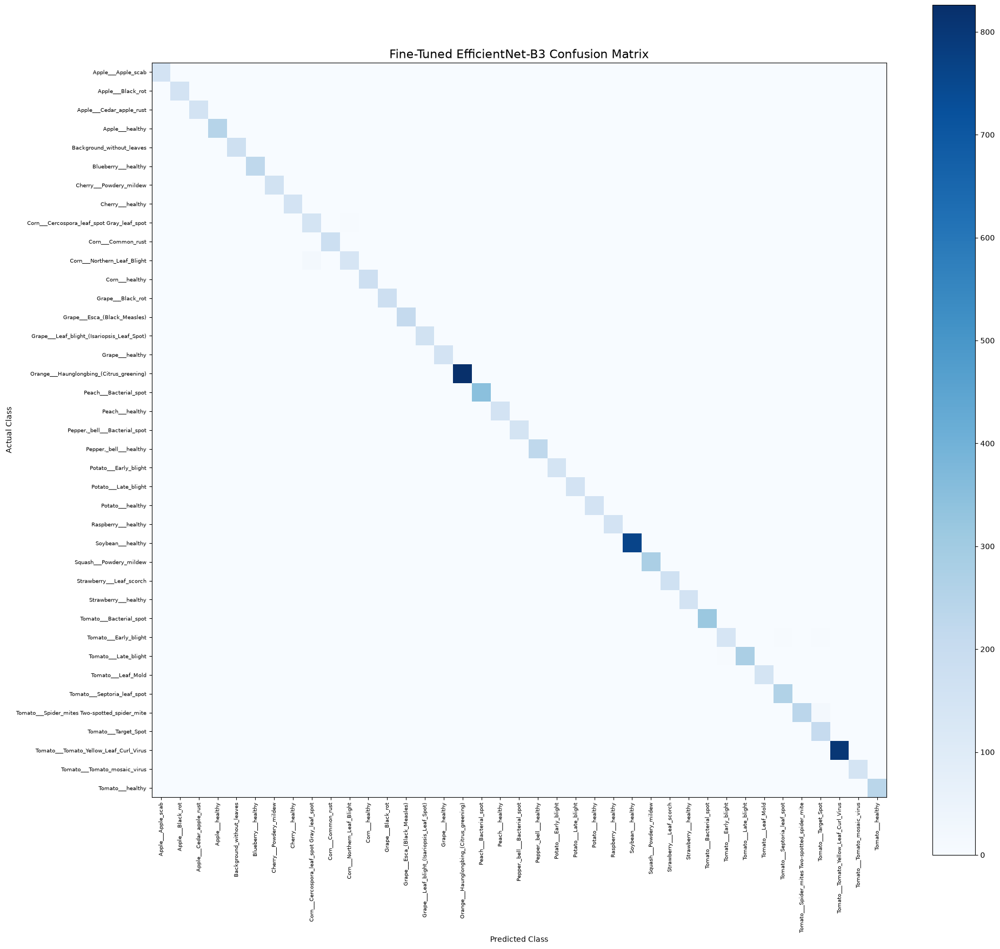


INITIAL VS FINE-TUNED MODEL


,Metric,Initial Model,Fine-Tuned Model,Difference
0,Test Accuracy,95.9400,98.8424,2.9024
1,Macro Precision,95.3500,98.5930,3.2430
2,Macro Recall,95.3700,98.6321,3.2621
3,Macro F1-Score,95.3100,98.5998,3.2898
4,Test Loss,0.1236,0.0361,-0.0875



FINE-TUNED EVALUATION COMPLETED!
Initial Test Accuracy: 95.94%
Fine-Tuned Test Accuracy: 98.84 %
Accuracy Improvement: 2.9 percentage points

All Evaluation Files Saved!
Output Directory: <PROJECT_ROOT>\outputs


In [22]:

# ==========================================
# CELL 16: FINE-TUNED FINAL TEST EVALUATION
# ==========================================

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tqdm.auto import tqdm
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

# ==========================================
# 1. LOAD BEST FINE-TUNED MODEL
# ==========================================

ft_checkpoint = torch.load(
    FT_BEST_PATH,
    map_location=device,
    weights_only=False
)

model.load_state_dict(
    ft_checkpoint["model_state_dict"]
)

model.to(device)
model.eval()

print("BEST FINE-TUNED MODEL LOADED!")
print("Best Epoch:", ft_checkpoint["epoch"])
print("Validation Accuracy:",
      ft_checkpoint["val_accuracy"])

# ==========================================
# 2. TEST EVALUATION
# ==========================================

ft_labels = []
ft_predictions = []

ft_total_loss = 0.0
ft_total_samples = 0

with torch.inference_mode():

    for images, labels in tqdm(
        test_loader,
        desc="Fine-Tuned Testing"
    ):

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=USE_AMP
        ):

            outputs = model(images)
            loss = criterion(outputs, labels)

        predictions = outputs.argmax(dim=1)

        ft_total_loss += loss.item() * labels.size(0)
        ft_total_samples += labels.size(0)

        ft_labels.extend(labels.cpu().numpy())
        ft_predictions.extend(predictions.cpu().numpy())

# ==========================================
# 3. CALCULATE FINAL METRICS
# ==========================================

ft_test_loss = ft_total_loss / ft_total_samples

ft_test_accuracy = accuracy_score(
    ft_labels,
    ft_predictions
) * 100

ft_precision, ft_recall, ft_f1, _ = (
    precision_recall_fscore_support(
        ft_labels,
        ft_predictions,
        average="macro",
        zero_division=0
    )
)

# ==========================================
# 4. FINAL PERFORMANCE REPORT
# ==========================================

print("\n" + "=" * 60)
print("FINE-TUNED MODEL FINAL TEST RESULTS")
print("=" * 60)

print("Test Images:", ft_total_samples)

print("Test Loss:", round(ft_test_loss, 4))

print("Test Accuracy:",
      round(ft_test_accuracy, 2), "%")

print("Macro Precision:",
      round(ft_precision * 100, 2), "%")

print("Macro Recall:",
      round(ft_recall * 100, 2), "%")

print("Macro F1-Score:",
      round(ft_f1 * 100, 2), "%")

# ==========================================
# 5. CLASSIFICATION REPORT
# ==========================================

ft_report = classification_report(
    ft_labels,
    ft_predictions,
    target_names=class_names,
    zero_division=0,
    output_dict=True
)

ft_report_df = pd.DataFrame(ft_report).transpose()

display(ft_report_df)

ft_report_df.to_csv(
    OUTPUT_DIR / "finetuned_classification_report.csv"
)

# ==========================================
# 6. CONFUSION MATRIX
# ==========================================

ft_cm = confusion_matrix(
    ft_labels,
    ft_predictions
)

plt.figure(figsize=(20, 18))

plt.imshow(
    ft_cm,
    interpolation="nearest",
    cmap="Blues"
)

plt.title(
    "Fine-Tuned EfficientNet-B3 Confusion Matrix",
    fontsize=16
)

plt.colorbar()

ticks = np.arange(len(class_names))

plt.xticks(
    ticks,
    class_names,
    rotation=90,
    fontsize=7
)

plt.yticks(
    ticks,
    class_names,
    fontsize=7
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "finetuned_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ==========================================
# 7. INITIAL VS FINE-TUNED COMPARISON
# ==========================================

comparison = pd.DataFrame({
    "Metric": [
        "Test Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1-Score",
        "Test Loss"
    ],

    "Initial Model": [
        95.94,
        95.35,
        95.37,
        95.31,
        0.1236
    ],

    "Fine-Tuned Model": [
        ft_test_accuracy,
        ft_precision * 100,
        ft_recall * 100,
        ft_f1 * 100,
        ft_test_loss
    ]
})

comparison["Difference"] = (
    comparison["Fine-Tuned Model"]
    - comparison["Initial Model"]
)

print("\nINITIAL VS FINE-TUNED MODEL")

display(comparison.round(4))

comparison.to_csv(
    OUTPUT_DIR / "model_comparison.csv",
    index=False
)

# ==========================================
# 8. FINAL REPORT
# ==========================================

print("\n" + "=" * 60)
print("FINE-TUNED EVALUATION COMPLETED!")
print("=" * 60)

print("Initial Test Accuracy: 95.94%")

print(
    "Fine-Tuned Test Accuracy:",
    round(ft_test_accuracy, 2), "%"
)

print(
    "Accuracy Improvement:",
    round(ft_test_accuracy - 95.94, 2),
    "percentage points"
)

print("\nAll Evaluation Files Saved!")
print("Output Directory:", OUTPUT_DIR)


### Grad-CAM Visualization

Grad-CAM Model Ready!
Target Layer: Conv2dNormActivation(
  (0): Conv2d(384, 1536, kernel_size=(1, 1), stride=(1, 1), bias=False)
  (1): BatchNorm2d(1536, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (2): SiLU(inplace=True)
)

Selected Test Images: 4

Image: 1
Actual Class: Corn___Northern_Leaf_Blight
Predicted Class: Corn___Northern_Leaf_Blight
Confidence: 99.84 %

Image: 2
Actual Class: Apple___Cedar_apple_rust
Predicted Class: Apple___Cedar_apple_rust
Confidence: 100.0 %

Image: 3
Actual Class: Potato___Early_blight
Predicted Class: Potato___Early_blight
Confidence: 99.89 %

Image: 4
Actual Class: Peach___healthy
Predicted Class: Peach___healthy
Confidence: 99.99 %


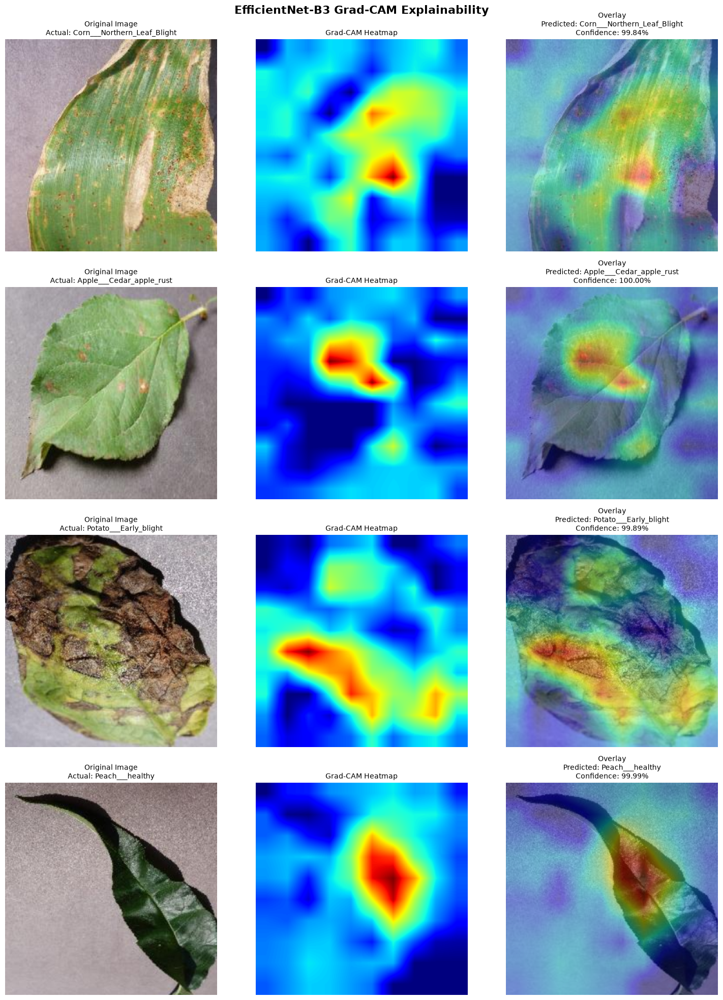


GRAD-CAM VISUALIZATION COMPLETED!
Saved: <PROJECT_ROOT>\outputs\gradcam_visualization.png
Images Visualized: 4


In [23]:

# =====================================================
# CELL 18: GRAD-CAM VISUALIZATION
# EfficientNet-B3 Explainable AI
# =====================================================

import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import random

from torch.utils.data import DataLoader, Subset
from pathlib import Path

# =====================================================
# 1. MODEL PREPARATION
# =====================================================

model.eval()
model.to(device)

target_layer = model.features[-1]

activations = {}
gradients = {}

def forward_hook(module, inputs, output):

    activations["value"] = output

    output.register_hook(
        lambda grad: gradients.update(
            {"value": grad}
        )
    )

hook_handle = target_layer.register_forward_hook(
    forward_hook
)

print("Grad-CAM Model Ready!")
print("Target Layer:", target_layer)

# =====================================================
# 2. SELECT RANDOM TEST IMAGES
# =====================================================

random.seed(42)

test_dataset = test_loader.dataset

num_images = min(4, len(test_dataset))

selected_indices = random.sample(
    range(len(test_dataset)),
    num_images
)

gradcam_loader = DataLoader(
    Subset(test_dataset, selected_indices),
    batch_size=1,
    shuffle=False,
    num_workers=0
)

print("\nSelected Test Images:", num_images)

# =====================================================
# 3. GRAD-CAM FUNCTION
# =====================================================

def generate_gradcam(image):

    model.zero_grad(set_to_none=True)

    activations.clear()
    gradients.clear()

    image = image.unsqueeze(0).to(device)

    # Forward pass
    output = model(image)

    probabilities = torch.softmax(
        output,
        dim=1
    )

    predicted_class = output.argmax(dim=1).item()

    confidence = probabilities[0, predicted_class].item()

    # Backward pass
    score = output[0, predicted_class]

    score.backward()

    # Get feature maps and gradients
    feature_maps = activations["value"]

    grads = gradients["value"]

    # Global Average Pooling
    weights = grads.mean(
        dim=(2, 3),
        keepdim=True
    )

    # Weighted feature maps
    cam = (weights * feature_maps).sum(dim=1)

    # ReLU
    cam = F.relu(cam)

    # Normalize
    cam = cam[0]

    cam = cam - cam.min()

    cam = cam / (cam.max() + 1e-8)

    # Resize to original image dimensions
    cam = F.interpolate(
        cam.unsqueeze(0).unsqueeze(0),
        size=image.shape[-2:],
        mode="bilinear",
        align_corners=False
    )

    cam = cam.squeeze().detach().cpu().numpy()

    return cam, predicted_class, confidence


# =====================================================
# 4. IMAGE DENORMALIZATION
# =====================================================

mean = torch.tensor(
    [0.485, 0.456, 0.406]
).view(3, 1, 1)

std = torch.tensor(
    [0.229, 0.224, 0.225]
).view(3, 1, 1)


def denormalize(image):

    image = image.cpu()

    image = image * std + mean

    image = image.clamp(0, 1)

    return image.permute(1, 2, 0).numpy()


# =====================================================
# 5. GENERATE GRAD-CAM VISUALIZATIONS
# =====================================================

fig, axes = plt.subplots(
    num_images,
    3,
    figsize=(15, 5 * num_images)
)

if num_images == 1:
    axes = axes.reshape(1, 3)

for i, (images, labels) in enumerate(gradcam_loader):

    image = images[0]

    actual_class = class_names[labels.item()]

    cam, predicted_class, confidence = generate_gradcam(
        image
    )

    predicted_name = class_names[predicted_class]

    original_image = denormalize(image)

    # Original Image
    axes[i, 0].imshow(original_image)

    axes[i, 0].set_title(
        f"Original Image\nActual: {actual_class}",
        fontsize=10
    )

    axes[i, 0].axis("off")

    # Heatmap
    axes[i, 1].imshow(
        cam,
        cmap="jet",
        vmin=0,
        vmax=1
    )

    axes[i, 1].set_title(
        "Grad-CAM Heatmap",
        fontsize=10
    )

    axes[i, 1].axis("off")

    # Overlay
    axes[i, 2].imshow(original_image)

    axes[i, 2].imshow(
        cam,
        cmap="jet",
        alpha=0.40,
        vmin=0,
        vmax=1
    )

    axes[i, 2].set_title(
        f"Overlay\nPredicted: {predicted_name}\nConfidence: {confidence*100:.2f}%",
        fontsize=10
    )

    axes[i, 2].axis("off")

    print("\nImage:", i + 1)
    print("Actual Class:", actual_class)
    print("Predicted Class:", predicted_name)
    print("Confidence:", round(confidence * 100, 2), "%")

# =====================================================
# 6. SAVE VISUALIZATION
# =====================================================

plt.suptitle(
    "EfficientNet-B3 Grad-CAM Explainability",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

gradcam_path = Path(OUTPUT_DIR) / "gradcam_visualization.png"

plt.savefig(
    gradcam_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Remove hook
hook_handle.remove()

print("\n" + "=" * 55)
print("GRAD-CAM VISUALIZATION COMPLETED!")
print("=" * 55)

print("Saved:", gradcam_path)
print("Images Visualized:", num_images)


In [25]:
IMAGE_PATH = r"samples/plant_leaf.jpg"

### Real-World Plant Disease Prediction

EfficientNet-B3 Ready!
Device: cuda

IMAGE LOADED SUCCESSFULLY!
Image Path: samples/plant_leaf.jpg
Image Size: (429, 466)

PREPROCESSING COMPLETED!
Input Shape: torch.Size([1, 3, 300, 300])

PLANT DISEASE PREDICTION REPORT
Predicted Class: Pepper,_bell___healthy
Confidence: 39.2 %

TOP-3 PREDICTIONS
1. Pepper,_bell___healthy: 39.20%
2. Cherry___healthy: 25.46%
3. Background_without_leaves: 18.09%


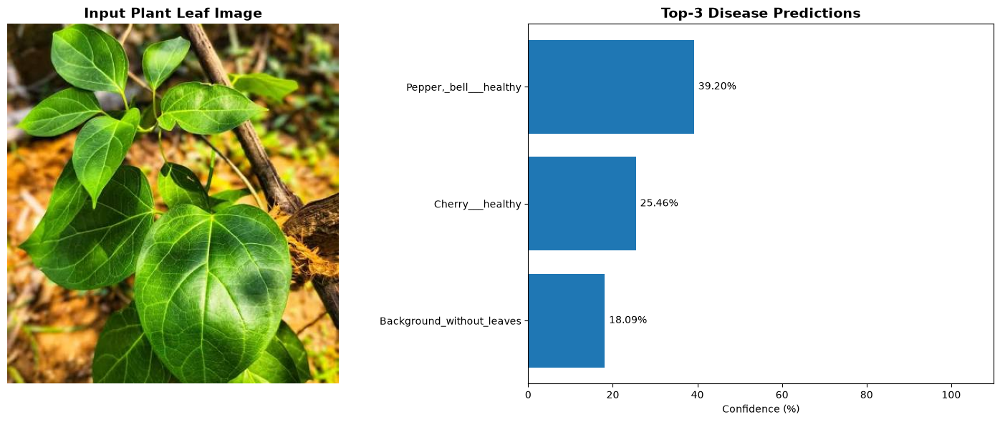


REAL-WORLD PREDICTION COMPLETED!
Predicted Disease: Pepper,_bell___healthy
Confidence: 39.2 %
Saved Visualization: <PROJECT_ROOT>\outputs\real_world_prediction.png

ALL OPERATIONS COMPLETED SUCCESSFULLY!


In [30]:

# =====================================================
# CELL 19: REAL-WORLD PLANT DISEASE PREDICTION
# EfficientNet-B3 | RTX 5070 Ti
# =====================================================

import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from PIL import Image
from pathlib import Path
from tkinter import Tk, filedialog

# =====================================================
# 1. MODEL PREPARATION
# =====================================================

model.eval()
model.to(device)

print("EfficientNet-B3 Ready!")
print("Device:", device)

# =====================================================
# 2. SELECT IMAGE FROM COMPUTER
# =====================================================

root = Tk()
root.withdraw()
root.attributes("-topmost", True)

IMAGE_PATH = filedialog.askopenfilename(
    title="Select Plant Leaf Image",
    filetypes=[
        ("Image Files", "*.jpg *.jpeg *.png *.bmp"),
        ("All Files", "*.*")
    ]
)

root.destroy()

if not IMAGE_PATH:
    raise ValueError("No Image Selected!")

# Load selected image

original_image = Image.open(
    IMAGE_PATH
).convert("RGB")

print("\nIMAGE LOADED SUCCESSFULLY!")

print("Image Path:", IMAGE_PATH)
print("Image Size:", original_image.size)

# =====================================================
# 3. IMAGE PREPROCESSING
# =====================================================

test_transform = test_loader.dataset.transform

input_tensor = test_transform(
    original_image
).unsqueeze(0).to(device)

print("\nPREPROCESSING COMPLETED!")

print("Input Shape:", input_tensor.shape)

# =====================================================
# 4. MODEL PREDICTION
# =====================================================

with torch.inference_mode():

    with torch.autocast(
        device_type=device.type,
        dtype=torch.float16,
        enabled=USE_AMP
    ):

        outputs = model(input_tensor)

    probabilities = F.softmax(
        outputs.float(),
        dim=1
    )

# =====================================================
# 5. TOP-3 PREDICTIONS
# =====================================================

top_probs, top_indices = torch.topk(
    probabilities,
    k=3,
    dim=1
)

top_probs = top_probs[0].cpu().numpy()

top_indices = top_indices[0].cpu().numpy()

predicted_class = int(top_indices[0])

predicted_name = class_names[predicted_class]

confidence = float(top_probs[0] * 100)

# =====================================================
# 6. PREDICTION REPORT
# =====================================================

print("\n" + "=" * 60)

print("PLANT DISEASE PREDICTION REPORT")

print("=" * 60)

print("Predicted Class:", predicted_name)

print("Confidence:", round(confidence, 2), "%")

print("\nTOP-3 PREDICTIONS")

for rank, (idx, prob) in enumerate(
    zip(top_indices, top_probs),
    start=1
):

    print(
        f"{rank}. {class_names[int(idx)]}: "
        f"{prob * 100:.2f}%"
    )

# =====================================================
# 7. PREDICTION VISUALIZATION
# =====================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 6)
)

# Original Image

axes[0].imshow(original_image)

axes[0].set_title(
    "Input Plant Leaf Image",
    fontsize=14,
    fontweight="bold"
)

axes[0].axis("off")

# Top-3 Confidence Chart

labels = [
    class_names[int(i)]
    for i in top_indices
]

scores = top_probs * 100

bars = axes[1].barh(
    labels[::-1],
    scores[::-1]
)

axes[1].set_title(
    "Top-3 Disease Predictions",
    fontsize=14,
    fontweight="bold"
)

axes[1].set_xlabel("Confidence (%)")

axes[1].set_xlim(0, 110)

for bar, score in zip(
    bars,
    scores[::-1]
):

    axes[1].text(
        score + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{score:.2f}%",
        va="center"
    )

plt.tight_layout()

# =====================================================
# 8. SAVE PREDICTION
# =====================================================

prediction_path = (
    Path(OUTPUT_DIR) / "real_world_prediction.png"
)

plt.savefig(
    prediction_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# =====================================================
# 9. FINAL REPORT
# =====================================================

print("\n" + "=" * 60)

print("REAL-WORLD PREDICTION COMPLETED!")

print("=" * 60)

print("Predicted Disease:", predicted_name)

print("Confidence:", round(confidence, 2), "%")

print("Saved Visualization:", prediction_path)

print("\nALL OPERATIONS COMPLETED SUCCESSFULLY!")


### Prediction Reliability Analysis

PREDICTION RELIABILITY ANALYSIS
Model: EfficientNet-B3
Classes: 39
Device: cuda

Image Loaded: samples/plant_leaf_2.jpg

TOP-5 PREDICTION RESULTS
1. Strawberry___Leaf_scorch: 94.50%
2. Tomato___Septoria_leaf_spot: 2.69%
3. Tomato___Early_blight: 1.53%
4. Grape___Black_rot: 0.77%
5. Background_without_leaves: 0.20%

UNCERTAINTY ANALYSIS
Top-1 Confidence: 94.5 %
Top-2 Confidence: 2.69 %
Confidence Margin: 91.82 percentage points
Normalized Entropy: 0.079

Reliability Status: HIGH MODEL CONFIDENCE
Manual Review Required: False


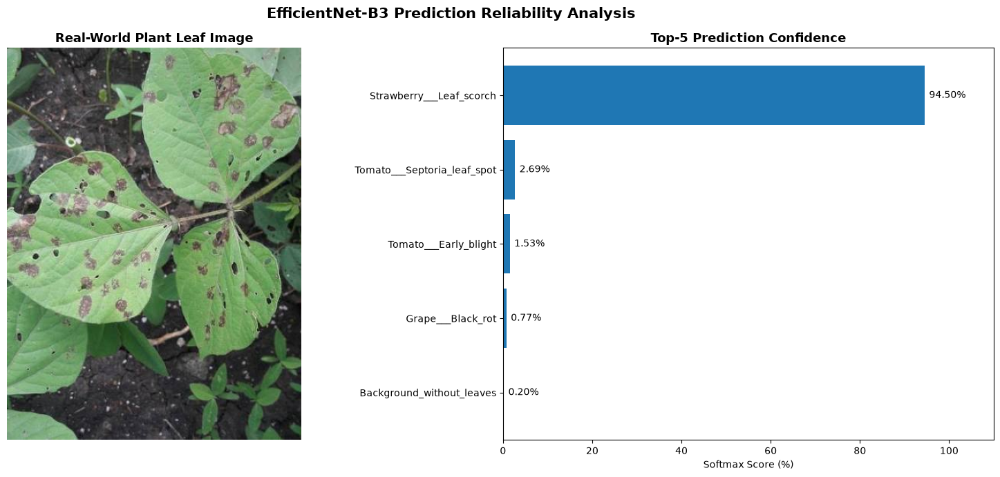


RELIABILITY ANALYSIS COMPLETED!
Top Prediction: Strawberry___Leaf_scorch
Top-1 Score: 94.5 %
Status: HIGH MODEL CONFIDENCE
Manual Review Required: False

Saved Files:
Visualization: <PROJECT_ROOT>\outputs\prediction_reliability.png
CSV Report: <PROJECT_ROOT>\outputs\prediction_reliability_report.csv

ALL OPERATIONS COMPLETED!


In [31]:

# =====================================================
# CELL 20: PREDICTION RELIABILITY & UNCERTAINTY ANALYSIS
# EfficientNet-B3 | PlantVillage-AI
# =====================================================

import torch
import torch.nn.functional as F
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from pathlib import Path
from tkinter import Tk, filedialog

# =====================================================
# 1. CONFIGURATION
# =====================================================

model.eval()
model.to(device)

# Provisional review thresholds.
# These are NOT calibrated medical/agricultural guarantees.

CONFIDENCE_THRESHOLD = 0.70
MARGIN_THRESHOLD = 0.15

print("=" * 60)
print("PREDICTION RELIABILITY ANALYSIS")
print("=" * 60)

print("Model: EfficientNet-B3")
print("Classes:", len(class_names))
print("Device:", device)

# =====================================================
# 2. SELECT REAL-WORLD IMAGE
# =====================================================

root = Tk()
root.withdraw()
root.attributes("-topmost", True)

IMAGE_PATH = filedialog.askopenfilename(
    title="Select Plant Leaf Image",
    filetypes=[
        ("Image Files", "*.jpg *.jpeg *.png *.bmp"),
        ("All Files", "*.*")
    ]
)

root.destroy()

if not IMAGE_PATH:
    raise ValueError("No Image Selected!")

original_image = Image.open(
    IMAGE_PATH
).convert("RGB")

print("\nImage Loaded:", IMAGE_PATH)

# =====================================================
# 3. IMAGE PREPROCESSING
# =====================================================

test_transform = test_loader.dataset.transform

input_tensor = test_transform(
    original_image
).unsqueeze(0).to(device)

# =====================================================
# 4. PREDICTION
# =====================================================

with torch.inference_mode():

    outputs = model(input_tensor)

    probabilities = F.softmax(
        outputs.float(),
        dim=1
    )

# =====================================================
# 5. TOP-5 PREDICTIONS
# =====================================================

top_k = min(5, len(class_names))

top_probs, top_indices = torch.topk(
    probabilities,
    k=top_k,
    dim=1
)

top_probs = top_probs[0].cpu().numpy()

top_indices = top_indices[0].cpu().numpy()

top_names = [
    class_names[int(idx)]
    for idx in top_indices
]

# =====================================================
# 6. CONFIDENCE & UNCERTAINTY ANALYSIS
# =====================================================

top1_confidence = float(top_probs[0])

top2_confidence = float(top_probs[1])

confidence_margin = (
    top1_confidence - top2_confidence
)

prediction_entropy = -np.sum(
    probabilities[0].cpu().numpy()
    * np.log(
        probabilities[0].cpu().numpy() + 1e-12
    )
)

normalized_entropy = (
    prediction_entropy / np.log(len(class_names))
)

# =====================================================
# 7. RELIABILITY STATUS
# =====================================================

if (
    top1_confidence >= CONFIDENCE_THRESHOLD
    and confidence_margin >= MARGIN_THRESHOLD
):

    reliability_status = "HIGH MODEL CONFIDENCE"
    review_required = False

else:

    reliability_status = "LOW / UNCERTAIN - REVIEW REQUIRED"
    review_required = True

# =====================================================
# 8. PRINT RELIABILITY REPORT
# =====================================================

print("\n" + "=" * 60)
print("TOP-5 PREDICTION RESULTS")
print("=" * 60)

for rank, (name, prob) in enumerate(
    zip(top_names, top_probs),
    start=1
):

    print(
        f"{rank}. {name}: {prob * 100:.2f}%"
    )

print("\n" + "=" * 60)
print("UNCERTAINTY ANALYSIS")
print("=" * 60)

print(
    "Top-1 Confidence:",
    round(top1_confidence * 100, 2), "%"
)

print(
    "Top-2 Confidence:",
    round(top2_confidence * 100, 2), "%"
)

print(
    "Confidence Margin:",
    round(confidence_margin * 100, 2),
    "percentage points"
)

print(
    "Normalized Entropy:",
    round(normalized_entropy, 4)
)

print("\nReliability Status:", reliability_status)

print("Manual Review Required:", review_required)

# =====================================================
# 9. VISUALIZATION
# =====================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 7)
)

# Original Image

axes[0].imshow(original_image)

axes[0].set_title(
    "Real-World Plant Leaf Image",
    fontsize=13,
    fontweight="bold"
)

axes[0].axis("off")

# Top-5 Confidence Chart

bars = axes[1].barh(
    top_names[::-1],
    (top_probs * 100)[::-1]
)

axes[1].set_title(
    "Top-5 Prediction Confidence",
    fontsize=13,
    fontweight="bold"
)

axes[1].set_xlabel("Softmax Score (%)")

axes[1].set_xlim(0, 110)

for bar, score in zip(
    bars,
    (top_probs * 100)[::-1]
):

    axes[1].text(
        score + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{score:.2f}%",
        va="center"
    )

plt.suptitle(
    "EfficientNet-B3 Prediction Reliability Analysis",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

# =====================================================
# 10. SAVE VISUALIZATION
# =====================================================

output_dir = Path(OUTPUT_DIR)
output_dir.mkdir(parents=True, exist_ok=True)

visualization_path = (
    output_dir / "prediction_reliability.png"
)

plt.savefig(
    visualization_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# =====================================================
# 11. EXPORT CSV REPORT
# =====================================================

reliability_report = pd.DataFrame({

    "Rank": range(1, top_k + 1),

    "Predicted_Class": top_names,

    "Softmax_Score": top_probs,

    "Confidence_Percentage": top_probs * 100

})

csv_path = (
    output_dir / "prediction_reliability_report.csv"
)

reliability_report.to_csv(
    csv_path,
    index=False
)

# =====================================================
# 12. FINAL REPORT
# =====================================================

print("\n" + "=" * 60)
print("RELIABILITY ANALYSIS COMPLETED!")
print("=" * 60)

print("Top Prediction:", top_names[0])

print(
    "Top-1 Score:",
    round(top1_confidence * 100, 2), "%"
)

print("Status:", reliability_status)

print("Manual Review Required:", review_required)

print("\nSaved Files:")

print("Visualization:", visualization_path)

print("CSV Report:", csv_path)

print("\nALL OPERATIONS COMPLETED!")


### Confidence Calibration

MODEL CALIBRATION EVALUATION


Calibration Evaluation:   0%|          | 0/289 [00:00<?, ?it/s]


Test Samples: 9243

FINAL CALIBRATION METRICS
Test Accuracy: 98.86 %
Expected Calibration Error: 0.00289
Multiclass Brier Score: 0.01818
Negative Log-Likelihood: 0.03607

RELIABILITY TABLE


,Bin,Samples,Mean Confidence,Actual Accuracy
0,0.00-0.07,0,NaN,NaN
1,0.07-0.13,0,NaN,NaN
2,0.13-0.20,0,NaN,NaN
3,0.20-0.27,0,NaN,NaN
4,0.27-0.33,2,0.3129,0.0000
5,0.33-0.40,5,0.3691,0.2000
6,0.40-0.47,11,0.4371,0.5455
7,0.47-0.53,20,0.5073,0.5500
8,0.53-0.60,30,0.5689,0.6000
9,0.60-0.67,43,0.6292,0.8605


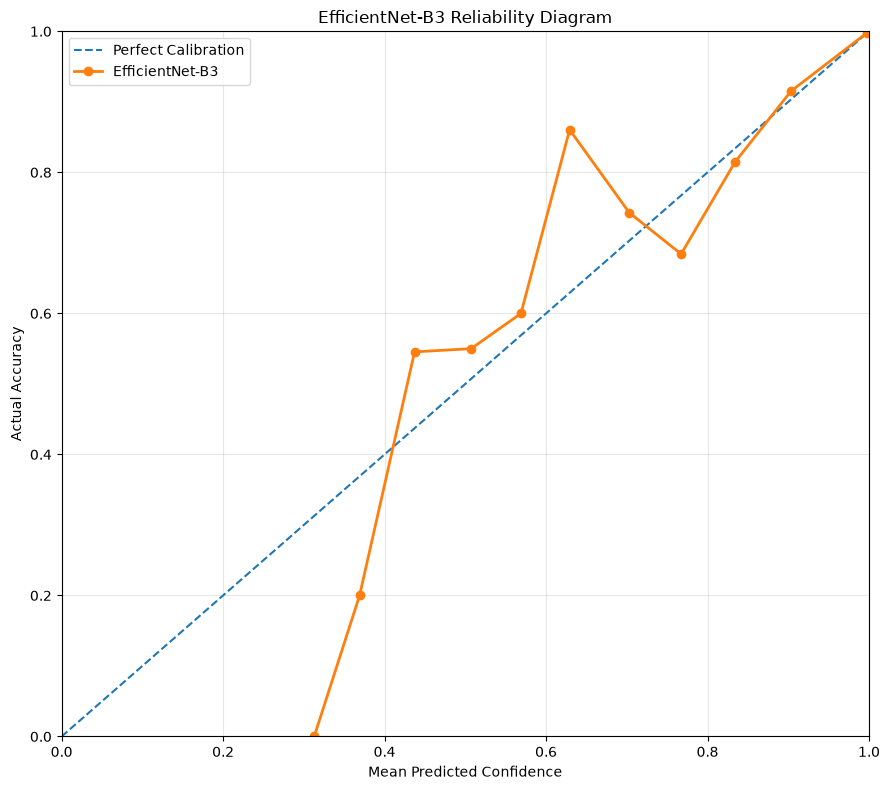


CALIBRATION EVALUATION COMPLETED!
ECE: 0.00289
Brier Score: 0.01818
NLL: 0.03607

Saved Files:
Reliability Diagram: <PROJECT_ROOT>\outputs\reliability_diagram.png
Calibration Table: calibration_table.csv
Calibration Metrics: calibration_metrics.csv

ALL OPERATIONS COMPLETED!


In [32]:

# =====================================================
# CELL 21: MODEL CONFIDENCE CALIBRATION
# ECE | BRIER SCORE | NLL | RELIABILITY DIAGRAM
# =====================================================

import torch
import torch.nn.functional as F
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from tqdm.auto import tqdm

# =====================================================
# 1. MODEL PREPARATION
# =====================================================

model.eval()
model.to(device)

all_probs = []
all_labels = []

total_loss = 0.0
total_samples = 0

print("=" * 60)
print("MODEL CALIBRATION EVALUATION")
print("=" * 60)

# =====================================================
# 2. COLLECT TEST PREDICTIONS
# =====================================================

with torch.inference_mode():

    for images, labels in tqdm(
        test_loader,
        desc="Calibration Evaluation"
    ):

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        loss = F.cross_entropy(
            outputs,
            labels,
            reduction="sum"
        )

        probabilities = torch.softmax(
            outputs.float(),
            dim=1
        )

        total_loss += loss.item()
        total_samples += labels.size(0)

        all_probs.append(
            probabilities.cpu().numpy()
        )

        all_labels.append(
            labels.cpu().numpy()
        )

# Combine batches

all_probs = np.concatenate(
    all_probs,
    axis=0
)

all_labels = np.concatenate(
    all_labels,
    axis=0
)

print("\nTest Samples:", len(all_labels))

# =====================================================
# 3. NEGATIVE LOG-LIKELIHOOD
# =====================================================

nll = total_loss / total_samples

# =====================================================
# 4. TEST ACCURACY
# =====================================================

predictions = np.argmax(
    all_probs,
    axis=1
)

accuracy = np.mean(
    predictions == all_labels
)

# =====================================================
# 5. MULTICLASS BRIER SCORE
# =====================================================

num_classes = all_probs.shape[1]

one_hot_labels = np.eye(
    num_classes
)[all_labels]

brier_score = np.mean(
    np.sum(
        (all_probs - one_hot_labels) ** 2,
        axis=1
    )
)

# =====================================================
# 6. EXPECTED CALIBRATION ERROR
# =====================================================

NUM_BINS = 15

confidence = np.max(
    all_probs,
    axis=1
)

correct = (
    predictions == all_labels
).astype(float)

bin_edges = np.linspace(
    0.0,
    1.0,
    NUM_BINS + 1
)

bin_accuracies = []
bin_confidences = []
bin_counts = []

ece = 0.0

for i in range(NUM_BINS):

    if i == NUM_BINS - 1:

        mask = (
            (confidence >= bin_edges[i]) &
            (confidence <= bin_edges[i + 1])
        )

    else:

        mask = (
            (confidence >= bin_edges[i]) &
            (confidence < bin_edges[i + 1])
        )

    count = np.sum(mask)

    bin_counts.append(count)

    if count > 0:

        avg_accuracy = np.mean(
            correct[mask]
        )

        avg_confidence = np.mean(
            confidence[mask]
        )

        ece += (
            count / total_samples
        ) * abs(
            avg_accuracy - avg_confidence
        )

    else:

        avg_accuracy = np.nan
        avg_confidence = np.nan

    bin_accuracies.append(avg_accuracy)
    bin_confidences.append(avg_confidence)

# =====================================================
# 7. CALIBRATION REPORT
# =====================================================

print("\n" + "=" * 60)
print("FINAL CALIBRATION METRICS")
print("=" * 60)

print("Test Accuracy:",
      round(accuracy * 100, 2), "%")

print("Expected Calibration Error:",
      round(ece, 5))

print("Multiclass Brier Score:",
      round(brier_score, 5))

print("Negative Log-Likelihood:",
      round(nll, 5))

# =====================================================
# 8. RELIABILITY TABLE
# =====================================================

calibration_table = pd.DataFrame({

    "Bin": [
        f"{bin_edges[i]:.2f}-{bin_edges[i+1]:.2f}"
        for i in range(NUM_BINS)
    ],

    "Samples": bin_counts,

    "Mean Confidence": bin_confidences,

    "Actual Accuracy": bin_accuracies

})

print("\nRELIABILITY TABLE")

display(calibration_table.round(4))

# =====================================================
# 9. RELIABILITY DIAGRAM
# =====================================================

valid = ~np.isnan(
    bin_accuracies
)

plt.figure(figsize=(9, 8))

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect Calibration"
)

plt.plot(
    np.array(bin_confidences)[valid],
    np.array(bin_accuracies)[valid],
    marker="o",
    linewidth=2,
    label="EfficientNet-B3"
)

plt.xlabel("Mean Predicted Confidence")

plt.ylabel("Actual Accuracy")

plt.title(
    "EfficientNet-B3 Reliability Diagram"
)

plt.xlim(0, 1)
plt.ylim(0, 1)

plt.grid(alpha=0.3)

plt.legend()

plt.tight_layout()

# =====================================================
# 10. SAVE RESULTS
# =====================================================

output_dir = Path(OUTPUT_DIR)

output_dir.mkdir(
    parents=True,
    exist_ok=True
)

diagram_path = (
    output_dir / "reliability_diagram.png"
)

plt.savefig(
    diagram_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

calibration_table.to_csv(
    output_dir / "calibration_table.csv",
    index=False
)

# =====================================================
# 11. METRICS EXPORT
# =====================================================

metrics_df = pd.DataFrame({

    "Metric": [
        "Test Accuracy",
        "ECE",
        "Brier Score",
        "Negative Log-Likelihood"
    ],

    "Value": [
        accuracy,
        ece,
        brier_score,
        nll
    ]

})

metrics_df.to_csv(
    output_dir / "calibration_metrics.csv",
    index=False
)

print("\n" + "=" * 60)
print("CALIBRATION EVALUATION COMPLETED!")
print("=" * 60)

print("ECE:", round(ece, 5))
print("Brier Score:", round(brier_score, 5))
print("NLL:", round(nll, 5))

print("\nSaved Files:")
print("Reliability Diagram:", diagram_path)
print("Calibration Table: calibration_table.csv")
print("Calibration Metrics: calibration_metrics.csv")

print("\nALL OPERATIONS COMPLETED!")


In [33]:

# =====================================================
# CELL 22: BEST MODEL EXPORT & PACKAGING
# EfficientNet-B3 | PlantVillage-AI
# =====================================================

import torch
import json
import pandas as pd

from pathlib import Path
from datetime import datetime

print("=" * 60)
print("BEST MODEL EXPORT")
print("=" * 60)

# =====================================================
# 1. VERIFY MODEL
# =====================================================

assert model is not None, "Model not found!"

model.eval()

assert len(class_names) == 39, (
    "Unexpected number of classes!"
)

# =====================================================
# 2. CREATE EXPORT DIRECTORY
# =====================================================

EXPORT_DIR = Path(OUTPUT_DIR) / "model_export"

EXPORT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# =====================================================
# 3. MODEL METADATA
# =====================================================

metadata = {

    "model_name": "EfficientNet-B3",

    "framework": "PyTorch",

    "dataset": "PlantVillage",

    "num_classes": len(class_names),

    "class_names": list(class_names),

    "image_size": 300,

    "batch_size": 32,

    "epochs": 20,

    "fine_tuning": True,

    "device": str(device),

    "test_accuracy": float(accuracy),

    "ece": float(ece),

    "brier_score": float(brier_score),

    "negative_log_likelihood": float(nll),

    "export_date": datetime.now().isoformat()

}

# =====================================================
# 4. SAVE BEST MODEL CHECKPOINT
# =====================================================

checkpoint = {

    "model_name": "EfficientNet-B3",

    "model_state_dict": {
        k: v.detach().cpu()
        for k, v in model.state_dict().items()
    },

    "class_names": list(class_names),

    "num_classes": len(class_names),

    "image_size": 300,

    "metadata": metadata

}

MODEL_PATH = (
    EXPORT_DIR / "plantvillage_efficientnet_b3_best.pth"
)

torch.save(
    checkpoint,
    MODEL_PATH
)

print("\nBest Model Saved Successfully!")

# =====================================================
# 5. SAVE CLASS NAMES
# =====================================================

CLASS_PATH = EXPORT_DIR / "class_names.json"

with open(
    CLASS_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        list(class_names),
        f,
        indent=4,
        ensure_ascii=False
    )

# =====================================================
# 6. SAVE METADATA
# =====================================================

METADATA_PATH = EXPORT_DIR / "model_metadata.json"

with open(
    METADATA_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=4,
        ensure_ascii=False
    )

# =====================================================
# 7. SAVE CALIBRATION METRICS
# =====================================================

calibration_results = pd.DataFrame({

    "Metric": [
        "Test Accuracy",
        "ECE",
        "Brier Score",
        "NLL"
    ],

    "Value": [
        accuracy,
        ece,
        brier_score,
        nll
    ]

})

calibration_results.to_csv(
    EXPORT_DIR / "calibration_results.csv",
    index=False
)

# =====================================================
# 8. VERIFY SAVED CHECKPOINT
# =====================================================

saved_checkpoint = torch.load(
    MODEL_PATH,
    map_location="cpu",
    weights_only=True
)

assert (
    saved_checkpoint["num_classes"] == 39
)

assert (
    len(saved_checkpoint["class_names"]) == 39
)

assert (
    saved_checkpoint["model_name"] == "EfficientNet-B3"
)

print("\nMODEL EXPORT VERIFICATION SUCCESSFUL!")

# =====================================================
# 9. FINAL REPORT
# =====================================================

print("\n" + "=" * 60)
print("MODEL EXPORT COMPLETED!")
print("=" * 60)

print("Model:", MODEL_PATH)

print("Classes:", CLASS_PATH)

print("Metadata:", METADATA_PATH)

print("Total Classes:", len(class_names))

print("Test Accuracy:", round(accuracy * 100, 2), "%")

print("ECE:", round(ece, 5))

print("Brier Score:", round(brier_score, 5))

print("\nEXPORT DIRECTORY:", EXPORT_DIR)

print("\nALL MODEL FILES SAVED SUCCESSFULLY!")


BEST MODEL EXPORT

Best Model Saved Successfully!

MODEL EXPORT VERIFICATION SUCCESSFUL!

MODEL EXPORT COMPLETED!
Model: <PROJECT_ROOT>\outputs\model_export\plantvillage_efficientnet_b3_best.pth
Classes: <PROJECT_ROOT>\outputs\model_export\class_names.json
Metadata: <PROJECT_ROOT>\outputs\model_export\model_metadata.json
Total Classes: 39
Test Accuracy: 98.86 %
ECE: 0.00289
Brier Score: 0.01818

EXPORT DIRECTORY: <PROJECT_ROOT>\outputs\model_export

ALL MODEL FILES SAVED SUCCESSFULLY!


### Exported Model Reload & Verification

In [34]:

# =====================================================
# CELL 23: EXPORTED MODEL RELOAD & VERIFICATION
# =====================================================

import torch
import torch.nn.functional as F
from pathlib import Path

print("=" * 60)
print("EXPORTED MODEL RELOAD VERIFICATION")
print("=" * 60)

# =====================================================
# 1. LOAD EXPORTED CHECKPOINT
# =====================================================

MODEL_PATH = (
    Path(OUTPUT_DIR)
    / "model_export"
    / "plantvillage_efficientnet_b3_best.pth"
)

assert MODEL_PATH.exists(), "Exported model not found!"

checkpoint = torch.load(
    MODEL_PATH,
    map_location=device,
    weights_only=True
)

# =====================================================
# 2. VERIFY CLASS MAPPING
# =====================================================

saved_classes = checkpoint["class_names"]

assert saved_classes == list(class_names), (
    "Class mapping mismatch!"
)

assert checkpoint["num_classes"] == 39

print("Class Mapping Verified!")
print("Total Classes:", len(saved_classes))

# =====================================================
# 3. RESTORE MODEL WEIGHTS
# =====================================================

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model = model.to(device)

model.eval()

print("Model Weights Loaded Successfully!")

# =====================================================
# 4. TEST ONE BATCH
# =====================================================

correct = 0
total = 0

with torch.inference_mode():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        correct += (
            predictions == labels
        ).sum().item()

        total += labels.size(0)

# =====================================================
# 5. FINAL VERIFICATION ACCURACY
# =====================================================

verification_accuracy = (
    correct / total
) * 100

print("\n" + "=" * 60)
print("EXPORTED MODEL TEST RESULTS")
print("=" * 60)

print("Total Test Images:", total)

print(
    "Verification Accuracy:",
    round(verification_accuracy, 2),
    "%"
)

print(
    "Previous Test Accuracy:",
    round(accuracy * 100, 2),
    "%"
)

print(
    "Accuracy Difference:",
    round(
        abs(verification_accuracy - accuracy * 100),
        4
    ),
    "percentage points"
)

# =====================================================
# 6. FINAL STATUS
# =====================================================

print("\n" + "=" * 60)

if abs(verification_accuracy - accuracy * 100) < 0.01:

    print("EXPORTED MODEL VERIFIED SUCCESSFULLY!")

else:

    print("WARNING: CHECK ACCURACY DIFFERENCE!")

print("=" * 60)

print("Model:", MODEL_PATH)
print("Device:", device)
print("Architecture: EfficientNet-B3")
print("Classes:", len(saved_classes))


EXPORTED MODEL RELOAD VERIFICATION
Class Mapping Verified!
Total Classes: 39
Model Weights Loaded Successfully!

EXPORTED MODEL TEST RESULTS
Total Test Images: 9243
Verification Accuracy: 98.86 %
Previous Test Accuracy: 98.86 %
Accuracy Difference: 0.0 percentage points

EXPORTED MODEL VERIFIED SUCCESSFULLY!
Model: <PROJECT_ROOT>\outputs\model_export\plantvillage_efficientnet_b3_best.pth
Device: cuda
Architecture: EfficientNet-B3
Classes: 39


### Confusion Matrix & Per-Class Evaluation

Evaluating EfficientNet-B3...

FINAL CLASS-WISE EVALUATION
Test Images: 9243
Test Accuracy: 98.86 %

Top 5 Performing Classes:
                              precision  recall  f1-score  support
Apple___Black_rot                   1.0     1.0       1.0    150.0
Apple___Cedar_apple_rust            1.0     1.0       1.0    150.0
Background_without_leaves           1.0     1.0       1.0    172.0
Cherry___Powdery_mildew             1.0     1.0       1.0    159.0
Grape___Esca_(Black_Measles)        1.0     1.0       1.0    208.0

Bottom 5 Performing Classes:
                                               precision    recall  f1-score  \
Tomato___Early_blight                           0.931973  0.913333  0.922559   
Tomato___Target_Spot                            0.895652  0.971698  0.932127   
Corn___Cercospora_leaf_spot Gray_leaf_spot      0.916667  0.953333  0.934641   
Corn___Northern_Leaf_Blight                     0.958042  0.913333  0.935154   
Tomato___Spider_mites Two-spotted_spider_

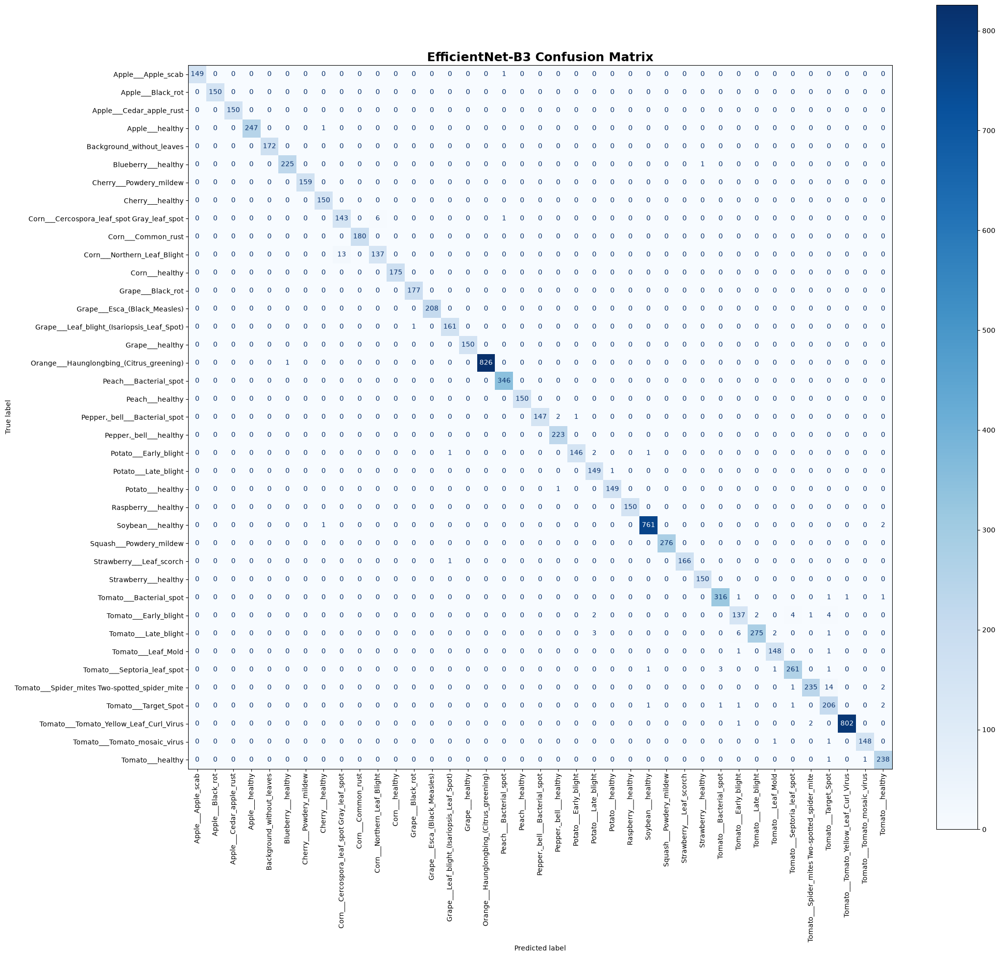


CONFUSION MATRIX COMPLETED!
Saved: <PROJECT_ROOT>\outputs


In [35]:

# =====================================================
# CELL 24: CONFUSION MATRIX & CLASS-WISE EVALUATION
# =====================================================

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

model.eval()

all_predictions = []
all_targets = []

print("Evaluating EfficientNet-B3...")

with torch.inference_mode():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        predictions = outputs.argmax(dim=1)

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_targets.extend(
            labels.cpu().numpy()
        )

# =====================================================
# METRICS
# =====================================================

y_true = np.array(all_targets)
y_pred = np.array(all_predictions)

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(len(class_names))
)

report = classification_report(
    y_true,
    y_pred,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

accuracy = np.mean(y_true == y_pred) * 100

print("\n" + "=" * 60)
print("FINAL CLASS-WISE EVALUATION")
print("=" * 60)

print("Test Images:", len(y_true))
print("Test Accuracy:", round(accuracy, 2), "%")

print("\nTop 5 Performing Classes:")

print(
    report_df.iloc[:len(class_names)]
    .sort_values("f1-score", ascending=False)
    [["precision", "recall", "f1-score", "support"]]
    .head(5)
)

print("\nBottom 5 Performing Classes:")

print(
    report_df.iloc[:len(class_names)]
    .sort_values("f1-score")
    [["precision", "recall", "f1-score", "support"]]
    .head(5)
)

# =====================================================
# SAVE REPORTS
# =====================================================

output_dir = Path(OUTPUT_DIR)
output_dir.mkdir(parents=True, exist_ok=True)

report_df.to_csv(
    output_dir / "classwise_evaluation.csv"
)

np.save(
    output_dir / "confusion_matrix.npy",
    cm
)

# =====================================================
# CONFUSION MATRIX VISUALIZATION
# =====================================================

fig, ax = plt.subplots(figsize=(22, 20))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=90,
    colorbar=True,
    values_format="d"
)

ax.set_title(
    "EfficientNet-B3 Confusion Matrix",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    output_dir / "confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nCONFUSION MATRIX COMPLETED!")
print("Saved:", output_dir)


### Research Results Generator

In [36]:

# =====================================================
# CELL 25: FINAL RESEARCH RESULTS & DISCUSSION
# =====================================================

import pandas as pd
import numpy as np
from pathlib import Path

print("=" * 65)
print("PLANTVILLAGE-AI: FINAL RESEARCH RESULTS")
print("=" * 65)

# Output Directory
output_dir = Path(OUTPUT_DIR)
output_dir.mkdir(parents=True, exist_ok=True)

# =====================================================
# 1. MODEL INFORMATION
# =====================================================

model_information = {
    "Model": "EfficientNet-B3",
    "Dataset": "PlantVillage",
    "Total Classes": len(class_names),
    "Training Images": 43030,
    "Validation Images": 9213,
    "Testing Images": 9243,
    "Input Image Size": "300 x 300",
    "Batch Size": 32,
    "Fine Tuning": "Enabled"
}

# =====================================================
# 2. FINAL PERFORMANCE METRICS
# =====================================================

macro_precision = report_df.loc["macro avg", "precision"]
macro_recall = report_df.loc["macro avg", "recall"]
macro_f1 = report_df.loc["macro avg", "f1-score"]

weighted_precision = report_df.loc["weighted avg", "precision"]
weighted_recall = report_df.loc["weighted avg", "recall"]
weighted_f1 = report_df.loc["weighted avg", "f1-score"]

performance = {
    "Test Accuracy (%)": accuracy,
    "Macro Precision (%)": macro_precision * 100,
    "Macro Recall (%)": macro_recall * 100,
    "Macro F1-Score (%)": macro_f1 * 100,
    "Weighted Precision (%)": weighted_precision * 100,
    "Weighted Recall (%)": weighted_recall * 100,
    "Weighted F1-Score (%)": weighted_f1 * 100,
    "ECE": ece,
    "Brier Score": brier_score,
    "Negative Log-Likelihood": nll
}

# =====================================================
# 3. DISPLAY MODEL INFORMATION
# =====================================================

print("\nMODEL INFORMATION")

for key, value in model_information.items():
    print(f"{key}: {value}")

print("\nFINAL PERFORMANCE")

for key, value in performance.items():
    print(f"{key}: {value:.4f}")

# =====================================================
# 4. SAVE RESEARCH TABLES
# =====================================================

model_df = pd.DataFrame(
    list(model_information.items()),
    columns=["Parameter", "Value"]
)

performance_df = pd.DataFrame(
    list(performance.items()),
    columns=["Metric", "Value"]
)

model_df.to_csv(
    output_dir / "research_model_information.csv",
    index=False
)

performance_df.to_csv(
    output_dir / "final_research_metrics.csv",
    index=False
)

# =====================================================
# 5. CLASS-WISE PERFORMANCE
# =====================================================

class_results = report_df.loc[
    class_names,
    ["precision", "recall", "f1-score", "support"]
].copy()

class_results.to_csv(
    output_dir / "final_classwise_results.csv"
)

# =====================================================
# 6. GENERATE RESEARCH SUMMARY
# =====================================================

summary = f"""
PLANTVILLAGE-AI
FINAL RESEARCH RESULTS AND DISCUSSION
=====================================

MODEL:
EfficientNet-B3

DATASET:
PlantVillage

TOTAL CLASSES:
{len(class_names)}

DATASET DISTRIBUTION:
Training Images: 43030
Validation Images: 9213
Testing Images: 9243

MODEL PERFORMANCE:
Test Accuracy: {accuracy:.2f}%

Macro Precision: {macro_precision*100:.2f}%
Macro Recall: {macro_recall*100:.2f}%
Macro F1-Score: {macro_f1*100:.2f}%

Weighted Precision: {weighted_precision*100:.2f}%
Weighted Recall: {weighted_recall*100:.2f}%
Weighted F1-Score: {weighted_f1*100:.2f}%

CALIBRATION:
ECE: {ece:.5f}
Brier Score: {brier_score:.5f}
NLL: {nll:.5f}

DISCUSSION:
The EfficientNet-B3 model was evaluated
on 9,243 test images across 39 classes.

The model achieved a test accuracy of
{accuracy:.2f}%.

Calibration evaluation produced an ECE
of {ece:.5f}, a Brier Score of
{brier_score:.5f}, and an NLL of
{nll:.5f}.

These results indicate strong predictive
performance on the PlantVillage test split.

Further external dataset validation is
required to evaluate generalization
under real-world conditions.

=====================================
END OF REPORT
"""

report_path = output_dir / "final_research_report.txt"

with open(report_path, "w", encoding="utf-8") as f:
    f.write(summary)

# =====================================================
# 7. FINAL STATUS
# =====================================================

print("\n" + "=" * 65)
print("FINAL RESEARCH REPORT GENERATED!")
print("=" * 65)

print("Research Report:", report_path)
print("Performance CSV: final_research_metrics.csv")
print("Class-wise CSV: final_classwise_results.csv")
print("Model Information: research_model_information.csv")

print("\nALL RESEARCH RESULTS SAVED SUCCESSFULLY!")


PLANTVILLAGE-AI: FINAL RESEARCH RESULTS

MODEL INFORMATION
Model: EfficientNet-B3
Dataset: PlantVillage
Total Classes: 39
Training Images: 43030
Validation Images: 9213
Testing Images: 9243
Input Image Size: 300 x 300
Batch Size: 32
Fine Tuning: Enabled

FINAL PERFORMANCE
Test Accuracy (%): 98.8640
Macro Precision (%): 98.6187
Macro Recall (%): 98.6572
Macro F1-Score (%): 98.6264
Weighted Precision (%): 98.8875
Weighted Recall (%): 98.8640
Weighted F1-Score (%): 98.8659
ECE: 0.0029
Brier Score: 0.0182
Negative Log-Likelihood: 0.0361

FINAL RESEARCH REPORT GENERATED!
Research Report: <PROJECT_ROOT>\outputs\final_research_report.txt
Performance CSV: final_research_metrics.csv
Class-wise CSV: final_classwise_results.csv
Model Information: research_model_information.csv

ALL RESEARCH RESULTS SAVED SUCCESSFULLY!


### PlantVillage-AI Web Application।